# Haplotype-resolved CpG methylation of EGFR-amplified glioblastoma (Figure 5)

This notebook contains the complete methylation analysis behind **Figure 5**, from the per-CpG methylation
tables to the final panels. Every figure is produced by a cell in this notebook and is saved with its output,
so the analysis can be read top to bottom without running anything.

**Question.** In tumors where EGFR is amplified on ecDNA, the amplified copy of chromosome 7 can be told apart
from the other copy by phasing. Does the *amplified haplotype* have different CpG methylation from the
*chromosomal haplotype* of the same tumor, are those differences shared between tumors, and do they fall on
active regulatory elements?

| Figure 5 panel | What it shows | Section |
|---|---|---|
| A | Schematic of haplotype-resolved methylation | illustration (not generated here) |
| B | Fraction of each tumor's callable CpGs inside hypo-/hypermethylated DMRs | 7 |
| C | One tumor's methylation on the chromosomal vs. amplified haplotype, with its DMRs | 8 |
| D | Recurrent DMRs across tumors with published regulatory elements and brain H3K27ac | 9 |
| E, F | Matched-permutation enrichment of recurrent DMRs for H3K27ac and cCREs | 10 |

Supplementary analyses (probability-threshold and coverage QC, H3K27ac bin-size sensitivity, methylation at the
EGFR promoter and published regulatory elements, methylation around the reconstructed ecDNA) are in sections 5, 10-12.

### Analysis in brief
1. **Per-CpG tables** (input). For each tumor and its matched blood, methylation probabilities from PacBio HiFi
   reads were tallied per CpG, per haplotype (HP1/HP2 from WhatsHap phasing) and per phase set, at four
   confidence thresholds (see the Appendix for the script that builds these tables on the compute server).
2. **Which haplotype is amplified?** Within the amplified interval, the haplotype with several-fold more
   reads is the amplified one (>= 200 reads and a >= 1.5 coverage ratio required).
3. **Differential methylation.** CpGs covered by >= 8 reads on *both* haplotypes are tested with DSS
   (amplified vs. chromosomal; p < 0.001, |difference| >= 0.2, smoothing span 500 bp). A methylation call is
   used only if its probability is >= 0.8 (methylated) or <= 0.2 (unmethylated).
4. **Recurrence.** DMRs that overlap between tumors are merged; for each interval we count both how many tumors
   share it and in how many tumors it was *testable*.
5. **Enrichment.** Recurrent DMRs are compared with callability-matched random intervals for brain H3K27ac and
   ENCODE cCRE overlap (10,000 permutations).

### Requirements
Python (`numpy`, `pandas`, `matplotlib`, `pyBigWig` for the one-time H3K27ac extraction) and R with the Bioconductor
packages `DSS` and `bsseq`. The DSS step takes a few minutes; the permutation test several more.

## 1. Setup and parameters

Edit `DATA_DIR` to the folder containing the per-CpG tables (`<sample>_<Tumor|Blood>_master_cpg_table.csv.gz`),
the ENCODE cCRE BED files and the H3K27ac track. All thresholds used in the paper are set here.

In [5]:
from pathlib import Path
import shutil
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrow

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

# ============================================================
# EDIT THESE PATHS
# ============================================================

DATA_DIR = Path("ecDNA_meth")          # EDIT: folder with the per-CpG tables, cCRE BEDs and H3K27ac track
RUN_DSS_R_SCRIPT = Path("run_DSS.R")   # written to the working directory by the first cell of section 6

OUT_ROOT = DATA_DIR / "clean_dss_results"
OUT_ROOT.mkdir(parents=True, exist_ok=True)

# ============================================================
# CORE SETTINGS
# ============================================================

THRESHOLDS = ["none", "40pct", "20pct", "10pct"]
DSS_THRESHOLD = "20pct"

MIN_TOTAL_COV_FOR_CLASSIFICATION = 200
MIN_COV_RATIO = 1.5

# A CpG enters DSS only if BOTH haplotypes have at least this depth.
MIN_SITE_COVERAGE = 8

P_THRESHOLD = 0.001
DELTA = 0.20
SMOOTHING_SPAN = 500

# Recurrence settings
MIN_RECURRENCE_SAMPLES = 2
MIN_CPGS_TO_COUNT_AS_TESTABLE = 3

AMP = "#D73027"
OTHER = "#2C6DB2"
EGFR_C = "#8E44AD"
DARK = "#333333"

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "figure.dpi": 110,
})

## 2. Cohort and amplicon coordinates

One entry per tumor: the interval of the EGFR amplicon (and, for multi-segment ecDNAs, partner intervals) from
the copy-number and CoRAL reconstruction. Each locus is classified and analysed independently because HP1/HP2
labels are only meaningful inside one phase set. `GBM_ID` maps sample identifiers to the labels used in the figures.

In [2]:
SAMPLE_LOCI = {
    "UM116": [("chr7_EGFR", "chr7", 54_847_000, 55_866_000)],
    "UM124": [("chr7_EGFR", "chr7", 54_497_000, 55_546_500)],
    "UM130": [("chr7_EGFR", "chr7", 54_531_000, 55_510_000)],
    "UM137": [("chr7_EGFR", "chr7", 54_478_000, 56_025_000)],
   # "UM141": [("chr7_EGFR", "chr7", 54_497_000, 55_546_500)],
    "UM146": [("chr7_EGFR", "chr7", 54_415_000, 55_358_500)],
    "UM159": [("chr7_EGFR", "chr7", 54_579_000, 55_338_500)],
    "UM170": [("chr7_EGFR", "chr7", 54_827_000, 55_268_500)],
    "UM215": [
        ("chr7_EGFR", "chr7", 54_761_500, 55_396_500),
        ("chr7_partner", "chr7", 23_000_000, 23_899_999),
    ],
    # "UM220": [
    #     ("chr7_EGFR", "chr7", 54_700_000, 55_200_000),
    #     ("chr12_partner", "chr12", 57_400_000, 58_099_999),
    # ],
    "UM233": [("chr7_EGFR", "chr7", 54_775_000, 55_277_000)],
    "UM244": [
        ("chr7_EGFR", "chr7", 54_737_000, 55_296_500),
        ("chr1_partner", "chr1", 85_164_566, 85_367_536),
    ],
    "UM258": [
        ("chr7_EGFR", "chr7", 54_221_500, 55_665_000),
        ("chr7_partner_a", "chr7", 42_702_568, 42_930_014),
        ("chr7_partner_b", "chr7", 49_622_122, 49_916_311),
        ("chr1_partner", "chr1", 13_289_905, 13_799_999),
        ("chr5_partner", "chr5", 144_000_000, 144_499_999),
    ],
    "UM029": [
        ("chr7_EGFR", "chr7", 53_513_000, 56_375_000),
        ("chr7_partner", "chr7", 76_007_007, 76_207_007),
    ],
}

MAIN_EGFR_SAMPLES = list(SAMPLE_LOCI)
METHYLATION_SAMPLES = [
    s for s in MAIN_EGFR_SAMPLES
    if s not in {"UM141", "UM220"}
]

print(len(METHYLATION_SAMPLES), METHYLATION_SAMPLES)
EGFR_START = 55_019_017
EGFR_END = 55_211_628
EGFR_STRAND = "+"

print(f"{len(MAIN_EGFR_SAMPLES)} EGFR-amplified cases configured")

# Labels used in the figures
GBM_ID = {
    "UM029": "GBM01", "UM116": "GBM02", "UM124": "GBM03", "UM130": "GBM04", "UM137": "GBM05",
    "UM141": "GBM06", "UM146": "GBM07", "UM159": "GBM08", "UM164": "GBM09", "UM165": "GBM10",
    "UM170": "GBM11", "UM176": "GBM12", "UM177": "GBM13", "UM209": "GBM14", "UM215": "GBM15",
    "UM220": "GBM16", "UM221": "GBM17", "UM229": "GBM18", "UM233": "GBM19", "UM244": "GBM20",
    "UM245": "GBM21", "UM258": "GBM22",
}

12 ['UM116', 'UM124', 'UM130', 'UM137', 'UM146', 'UM159', 'UM170', 'UM215', 'UM233', 'UM244', 'UM258', 'UM029']
12 EGFR-amplified cases configured


## 3. Load the per-CpG tables

Each table has one row per CpG position, haplotype (`hp`), phase set (`ps`) and confidence threshold, with `N`
(reads covering the CpG) and `X` (reads called methylated). Thresholds `40pct`, `20pct` and `10pct` keep only
calls with methylation probability within 40%, 20% or 10% of 0 or 1; `none` keeps every call (majority rule).
The paper's primary threshold is `20pct` (probability >= 0.8 or <= 0.2).

In [6]:
REQUIRED_COLS = {"chrom", "pos", "ps", "hp", "threshold", "N", "X"}
MASTER = {}

for sample in MAIN_EGFR_SAMPLES:
    MASTER[sample] = {}
    for tissue in ["Tumor", "Blood"]:
        path = DATA_DIR / f"{sample}_{tissue}_master_cpg_table.csv.gz"

        if not path.exists():
            print(f"[{sample}] {tissue}: MISSING {path.name}")
            MASTER[sample][tissue] = None
            continue

        df = pd.read_csv(path)
        missing = REQUIRED_COLS - set(df.columns)
        if missing:
            raise ValueError(f"{path.name} missing columns: {sorted(missing)}")

        MASTER[sample][tissue] = df

        print(
            f"[{sample}] {tissue}: {len(df):,} rows | "
            f"{df['pos'].nunique():,} unique positions | "
            f"thresholds={sorted(df['threshold'].astype(str).unique())}"
        )

[UM116] Tumor: 1,599,473 rows | 200,825 unique positions | thresholds=['10pct', '20pct', '40pct', 'none']
[UM116] Blood: 1,526,919 rows | 197,928 unique positions | thresholds=['10pct', '20pct', '40pct', 'none']
[UM124] Tumor: 1,342,663 rows | 169,008 unique positions | thresholds=['10pct', '20pct', '40pct', 'none']
[UM124] Blood: 1,323,585 rows | 168,735 unique positions | thresholds=['10pct', '20pct', '40pct', 'none']
[UM130] Tumor: 1,515,806 rows | 191,305 unique positions | thresholds=['10pct', '20pct', '40pct', 'none']
[UM130] Blood: 1,481,202 rows | 191,275 unique positions | thresholds=['10pct', '20pct', '40pct', 'none']
[UM137] Tumor: 1,313,587 rows | 167,005 unique positions | thresholds=['10pct', '20pct', '40pct', 'none']
[UM137] Blood: 1,178,013 rows | 164,140 unique positions | thresholds=['10pct', '20pct', '40pct', 'none']
[UM146] Tumor: 1,224,711 rows | 155,981 unique positions | thresholds=['10pct', '20pct', '40pct', 'none']
[UM146] Blood: 1,189,333 rows | 154,580 unique

## 4. Which haplotype carries the amplicon?

Inside the amplified interval the amplified haplotype is read several-fold more often than the other. For each phase
set we compare total read depth on the two haplotypes: the higher-coverage haplotype is labelled *amplified* and
the other *chromosomal*. Phase sets with fewer than 200 reads in the interval, or a coverage ratio below 1.5,
are not used.

In [7]:
def classify_locus(tumor_full, chrom, start, end):
    sub = tumor_full[tumor_full["chrom"] == chrom]
    classification = {}

    for ps, ps_df in sub.groupby("ps"):
        in_locus = ps_df[ps_df["pos"].between(start, end)]
        hp_cov = in_locus.groupby("hp")["N"].sum()

        if len(hp_cov) < 2:
            continue
        if hp_cov.sum() < MIN_TOTAL_COV_FOR_CLASSIFICATION:
            continue

        hp_sorted = hp_cov.sort_values(ascending=False)
        hi = float(hp_sorted.iloc[0])
        lo = max(float(hp_sorted.iloc[1]), 1e-9)

        if hi / lo < MIN_COV_RATIO:
            continue

        classification[ps] = {
            "amp_hp": int(hp_sorted.index[0]),
            "other_hp": int(hp_sorted.index[1]),
            "amp_total_N": hi,
            "other_total_N": lo,
            "coverage_ratio": hi / lo,
        }

    return classification


CLASSIFICATION = {}
class_rows = []

for sample, loci in SAMPLE_LOCI.items():
    tumor = MASTER[sample]["Tumor"]
    if tumor is None:
        continue

    tumor_full = tumor[tumor["threshold"] == "none"]

    for locus_name, chrom, start, end in loci:
        cls = classify_locus(tumor_full, chrom, start, end)
        CLASSIFICATION[(sample, locus_name)] = cls

        if not cls:
            class_rows.append({
                "sample": sample, "locus": locus_name, "chrom": chrom,
                "start": start, "end": end, "ps": None,
                "amp_hp": None, "other_hp": None, "coverage_ratio": np.nan,
            })
            continue

        for ps, info in cls.items():
            class_rows.append({
                "sample": sample, "locus": locus_name, "chrom": chrom,
                "start": start, "end": end, "ps": ps, **info,
            })

classification_df = pd.DataFrame(class_rows)
classification_df.to_csv(OUT_ROOT / "haplotype_classification.csv", index=False)
display(classification_df)

,sample,locus,chrom,start,end,ps,amp_hp,other_hp,amp_total_N,other_total_N,coverage_ratio
0,UM116,chr7_EGFR,chr7,54847000,55866000,54833149.0,2.0,1.0,150200.0,12499.0,12.016961
1,UM116,chr7_EGFR,chr7,54847000,55866000,54959525.0,1.0,2.0,134169.0,12154.0,11.039082
2,UM116,chr7_EGFR,chr7,54847000,55866000,55053566.0,2.0,1.0,5005175.0,429925.0,11.641972
3,UM116,chr7_EGFR,chr7,54847000,55866000,55622226.0,1.0,2.0,1830532.0,143158.0,12.786795
4,UM124,chr7_EGFR,chr7,54497000,55546500,53035429.0,2.0,1.0,42796928.0,446771.0,95.791643
5,UM124,chr7_EGFR,chr7,54497000,55546500,55553555.0,2.0,1.0,5547.0,2925.0,1.896410
6,UM130,chr7_EGFR,chr7,54531000,55510000,53260527.0,2.0,1.0,1351094.0,70103.0,19.272984
7,UM130,chr7_EGFR,chr7,54531000,55510000,54761673.0,1.0,2.0,6951998.0,342717.0,20.284952
8,UM137,chr7_EGFR,chr7,54478000,56025000,53720586.0,2.0,1.0,30029512.0,466763.0,64.335674
9,UM137,chr7_EGFR,chr7,54478000,56025000,55903679.0,1.0,2.0,2009216.0,63086.0,31.848841


Two helpers used throughout: `build_haplotype_table()` returns per-CpG counts for one haplotype group within a
locus, respecting each phase set's own HP labelling; `apply_joint_coverage_filter()` keeps a CpG only if **both**
haplotypes have at least `MIN_SITE_COVERAGE` reads at that exact position.

In [8]:
def build_haplotype_table(df, chrom, start, end, classification, group, threshold_label):
    frames = []

    for ps, info in classification.items():
        hp = info["amp_hp"] if group == "amp" else info["other_hp"]

        sub = df[
            (df["chrom"] == chrom)
            & (df["ps"] == ps)
            & (df["hp"] == hp)
            & (df["threshold"] == threshold_label)
            & (df["pos"].between(start, end))
        ]

        if len(sub):
            frames.append(sub[["pos", "N", "X"]])

    if not frames:
        return pd.DataFrame(columns=["chr", "pos", "N", "X"])

    combined = pd.concat(frames, ignore_index=True)

    out = (
        combined.groupby("pos", as_index=False)
        .agg(N=("N", "sum"), X=("X", "sum"))
        .sort_values("pos")
        .reset_index(drop=True)
    )

    out.insert(0, "chr", chrom)
    return out


def apply_joint_coverage_filter(amp_df, other_df, min_cov=MIN_SITE_COVERAGE):
    merged = (
        amp_df[["chr", "pos", "N", "X"]]
        .rename(columns={"N": "amp_N", "X": "amp_X"})
        .merge(
            other_df[["chr", "pos", "N", "X"]].rename(
                columns={"N": "other_N", "X": "other_X"}
            ),
            on=["chr", "pos"],
            how="inner",
        )
    )

    if min_cov:
        merged = merged[
            (merged["amp_N"] >= min_cov)
            & (merged["other_N"] >= min_cov)
        ].copy()

    amp_f = merged[["chr", "pos", "amp_N", "amp_X"]].rename(
        columns={"amp_N": "N", "amp_X": "X"}
    )
    other_f = merged[["chr", "pos", "other_N", "other_X"]].rename(
        columns={"other_N": "N", "other_X": "X"}
    )

    return amp_f.reset_index(drop=True), other_f.reset_index(drop=True), merged.reset_index(drop=True)

## 5. Quality control (supplementary)

**Probability thresholds.** How many CpG positions and how much read support survive each confidence threshold
(`none` -> `10pct`).

In [10]:
retention_rows = []

for sample, loci in SAMPLE_LOCI.items():
    tumor = MASTER[sample]["Tumor"]
    if tumor is None:
        continue

    for locus_name, chrom, start, end in loci:
        cls = CLASSIFICATION.get((sample, locus_name), {})
        if not cls:
            continue

        for group_name, group in [("amplified", "amp"), ("chromosomal", "other")]:
            for threshold in THRESHOLDS:
                tab = build_haplotype_table(
                    tumor, chrom, start, end, cls, group, threshold
                )

                retention_rows.append({
                    "sample": sample,
                    "locus": locus_name,
                    "group": group_name,
                    "threshold": threshold,
                    "n_cpg_positions": tab["pos"].nunique(),
                    "total_N": tab["N"].sum(),
                    "median_site_N": tab["N"].median() if len(tab) else np.nan,
                })

retention_long = pd.DataFrame(retention_rows)

base = (
    retention_long[retention_long["threshold"] == "none"]
    [["sample", "locus", "group", "n_cpg_positions", "total_N"]]
    .rename(columns={
        "n_cpg_positions": "base_n_cpg_positions",
        "total_N": "base_total_N",
    })
)

retention_long = retention_long.merge(
    base, on=["sample", "locus", "group"], how="left"
)

retention_long["pct_cpg_positions_retained"] = (
    100 * retention_long["n_cpg_positions"] / retention_long["base_n_cpg_positions"]
)

retention_long["pct_total_N_retained"] = (
    100 * retention_long["total_N"] / retention_long["base_total_N"]
)

#retention_long.to_csv(OUT_ROOT / "threshold_retention_long.csv", index=False)

display(
    retention_long[
        retention_long["locus"] == "chr7_EGFR"
    ].sort_values(["sample", "group", "threshold"])
)

,sample,locus,group,threshold,n_cpg_positions,total_N,median_site_N,base_n_cpg_positions,base_total_N,pct_cpg_positions_retained,pct_total_N_retained
107,UM029,chr7_EGFR,amplified,10pct,57489,12982701,232.0,57632,22626887,99.751874,57.377318
106,UM029,chr7_EGFR,amplified,20pct,57560,16191509,298.0,57632,22626887,99.875069,71.558712
105,UM029,chr7_EGFR,amplified,40pct,57603,20660956,388.0,57632,22626887,99.949681,91.311527
104,UM029,chr7_EGFR,amplified,none,57632,22626887,427.0,57632,22626887,100.000000,100.000000
111,UM029,chr7_EGFR,chromosomal,10pct,55666,644748,9.0,56326,1109834,98.828250,58.094093
...,...,...,...,...,...,...,...,...,...,...,...
88,UM258,chr7_EGFR,amplified,none,28384,39631321,1541.0,28384,39631321,100.000000,100.000000
95,UM258,chr7_EGFR,chromosomal,10pct,27889,323443,11.0,28097,520930,99.259707,62.089532
94,UM258,chr7_EGFR,chromosomal,20pct,28045,390033,14.0,28097,520930,99.814927,74.872440
93,UM258,chr7_EGFR,chromosomal,40pct,28087,481136,17.0,28097,520930,99.964409,92.360970


In [11]:
threshold_summary = (
    retention_long[retention_long["locus"] == "chr7_EGFR"]
    .groupby(["threshold", "group"])
    .agg(
        median_cpg_retained=("pct_cpg_positions_retained", "median"),
        min_cpg_retained=("pct_cpg_positions_retained", "min"),
        max_cpg_retained=("pct_cpg_positions_retained", "max"),
        median_total_N_retained=("pct_total_N_retained", "median"),
    )
    .reset_index()
)

display(threshold_summary)

,threshold,group,median_cpg_retained,min_cpg_retained,max_cpg_retained,median_total_N_retained
0,10pct,amplified,99.919472,98.375305,100.000000,61.509793
1,10pct,chromosomal,99.263929,98.828250,99.976027,61.575651
2,20pct,amplified,99.952855,99.241809,100.000000,74.645712
3,20pct,chromosomal,99.841597,99.613120,99.994873,74.557401
4,40pct,amplified,99.986153,99.828504,100.000000,92.320039
5,40pct,chromosomal,99.977376,99.904130,100.000000,92.322362
6,none,amplified,100.000000,100.000000,100.000000,100.000000
7,none,chromosomal,100.000000,100.000000,100.000000,100.000000


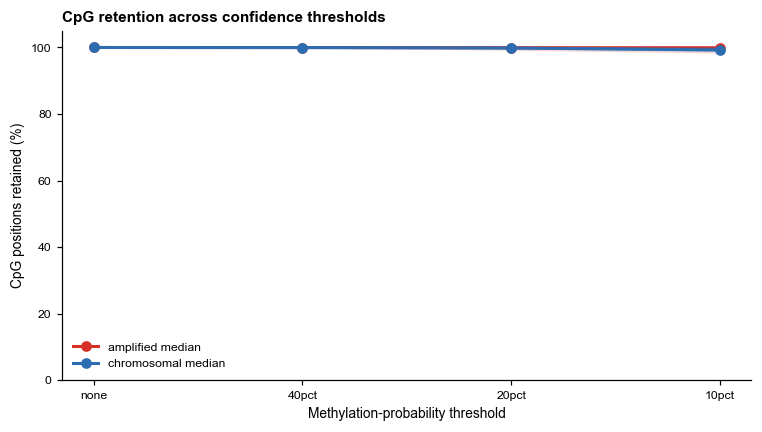

In [12]:
plot_df = retention_long[retention_long["locus"] == "chr7_EGFR"].copy()
xmap = {t: i for i, t in enumerate(THRESHOLDS)}

fig, ax = plt.subplots(figsize=(7, 4))

for group, color in [("amplified", AMP), ("chromosomal", OTHER)]:
    sub = plot_df[plot_df["group"] == group]

    for sample, sdf in sub.groupby("sample"):
        sdf = sdf.copy()
        sdf["x"] = sdf["threshold"].map(xmap)
        sdf = sdf.sort_values("x")
        ax.plot(
            sdf["x"],
            sdf["pct_cpg_positions_retained"],
            color=color,
            alpha=0.22,
            linewidth=0.8,
        )

    med = (
        sub.groupby("threshold")["pct_cpg_positions_retained"]
        .median()
        .reindex(THRESHOLDS)
    )

    ax.plot(
        range(len(THRESHOLDS)),
        med.values,
        color=color,
        marker="o",
        linewidth=2,
        label=f"{group} median",
    )

ax.set_xticks(range(len(THRESHOLDS)))
ax.set_xticklabels(THRESHOLDS)
ax.set_ylim(0, 105)
ax.set_ylabel("CpG positions retained (%)")
ax.set_xlabel("Methylation-probability threshold")
ax.set_title("CpG retention across confidence thresholds", loc="left", fontweight="bold")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(OUT_ROOT / "threshold_retention.png", dpi=250, bbox_inches="tight")
plt.show()

**Joint callability.** The most important check before DSS: how many CpGs remain once both haplotypes must have
at least `MIN_SITE_COVERAGE` reads at the same position.

In [13]:
coverage_rows = []

for sample, loci in SAMPLE_LOCI.items():
    tumor = MASTER[sample]["Tumor"]
    if tumor is None:
        continue

    for locus_name, chrom, start, end in loci:
        if locus_name != "chr7_EGFR":
            continue

        cls = CLASSIFICATION.get((sample, locus_name), {})
        if not cls:
            continue

        amp_raw = build_haplotype_table(
            tumor, chrom, start, end, cls, "amp", DSS_THRESHOLD
        )
        other_raw = build_haplotype_table(
            tumor, chrom, start, end, cls, "other", DSS_THRESHOLD
        )

        amp_f, other_f, joint = apply_joint_coverage_filter(
            amp_raw, other_raw, MIN_SITE_COVERAGE
        )

        raw_shared = amp_raw[["chr", "pos"]].merge(
            other_raw[["chr", "pos"]],
            on=["chr", "pos"],
            how="inner",
        )

        coverage_rows.append({
            "sample": sample,
            "locus": locus_name,
            "amp_n_cpg": len(amp_raw),
            "other_n_cpg": len(other_raw),
            "shared_n_cpg_before_cov": len(raw_shared),
            "shared_n_cpg_after_cov": len(joint),
            "pct_shared_sites_retained": (
                100 * len(joint) / len(raw_shared)
                if len(raw_shared) else np.nan
            ),
            "amp_median_N_before": amp_raw["N"].median() if len(amp_raw) else np.nan,
            "other_median_N_before": other_raw["N"].median() if len(other_raw) else np.nan,
            "amp_median_N_after": amp_f["N"].median() if len(amp_f) else np.nan,
            "other_median_N_after": other_f["N"].median() if len(other_f) else np.nan,
        })

coverage_df = pd.DataFrame(coverage_rows)
#coverage_df.to_csv(OUT_ROOT / "joint_coverage_qc.csv", index=False)

display(coverage_df.sort_values("pct_shared_sites_retained"))

,sample,locus,amp_n_cpg,other_n_cpg,shared_n_cpg_before_cov,shared_n_cpg_after_cov,pct_shared_sites_retained,amp_median_N_before,other_median_N_before,amp_median_N_after,other_median_N_after
3,UM137,chr7_EGFR,37266,36686,36392,27983,76.893273,704.0,11.0,759.0,12.0
11,UM029,chr7_EGFR,57560,56135,55553,45376,81.680557,298.0,12.0,317.0,13.0
8,UM233,chr7_EGFR,10995,10986,10818,9237,85.385469,226.0,24.0,337.0,26.0
5,UM159,chr7_EGFR,16420,16645,16362,14277,87.257059,172.0,13.0,179.0,13.0
6,UM170,chr7_EGFR,9865,10110,9805,8654,88.261091,480.0,13.0,493.0,13.0
2,UM130,chr7_EGFR,22540,22568,22187,19699,88.786226,275.0,14.0,284.0,14.0
10,UM258,chr7_EGFR,28347,28045,27724,25002,90.181792,1068.0,14.0,1129.0,14.0
1,UM124,chr7_EGFR,24091,23694,23505,21201,90.197830,1380.0,14.0,1421.0,15.0
4,UM146,chr7_EGFR,19672,19503,19203,17832,92.860491,352.0,14.0,359.0,15.0
7,UM215,chr7_EGFR,13794,13646,13475,12556,93.179963,1804.0,15.0,1850.5,15.0


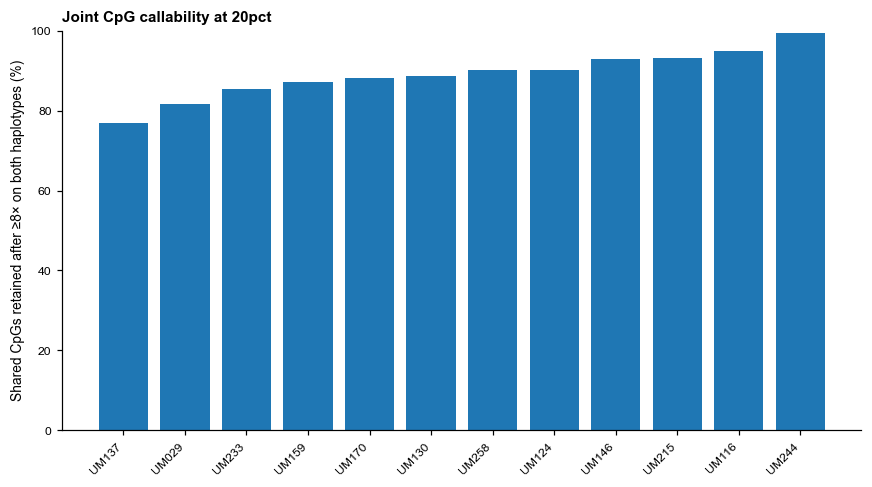

In [14]:
sub = coverage_df.sort_values("pct_shared_sites_retained")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(np.arange(len(sub)), sub["pct_shared_sites_retained"])
ax.set_xticks(np.arange(len(sub)))
ax.set_xticklabels(sub["sample"], rotation=45, ha="right")
ax.set_ylim(0, 100)
ax.set_ylabel(f"Shared CpGs retained after ≥{MIN_SITE_COVERAGE}× on both haplotypes (%)")
ax.set_title(f"Joint CpG callability at {DSS_THRESHOLD}", loc="left", fontweight="bold")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
#plt.savefig(OUT_ROOT / "joint_coverage_retention.png", dpi=250, bbox_inches="tight")
plt.show()

## 6. Differential methylation with DSS

For each tumor the filtered amplified and chromosomal tables are compared with DSS (`DMLtest` with smoothing, then
`callDMR`), using the R script below. DSS handles one sample per group with its no-replicate shrinkage estimator.
The exact input tables are saved next to each DMR file, so every DMR can be traced to the CpGs that support it.

The next cell writes the R script to the working directory.

In [15]:
%%writefile run_DSS.R
#!/usr/bin/env Rscript
#
# run_DSS.R -- standalone, dependency-isolated DSS runner.
#
# Takes two per-CpG count tables (one per group -- e.g. amplified vs.
# chromosomal haplotype in tumor) and runs DSS's no-replicate two-group
# DML test + DMR calling. Designed to be called as a subprocess from
# Python so nothing needs rpy2's compiled bridge.
#
# Corresponds to Methods -> "Haplotype-resolved CpG methylation analysis":
# DSS (DMLtest then callDMR), p.threshold=0.001, delta=0.2,
# smoothing.span=500, minCG=3, minlen=50, dis.merge=50, pct.sig=0.5.
#
# Input CSVs must have exactly these columns (header row required):
#   chr   - chromosome, e.g. "chr7"
#   pos   - 1-based genomic position of the CpG
#   N     - total (coverage) read count at that CpG in this group
#   X     - methylated read count at that CpG in this group
#
# Usage:
#   Rscript run_DSS.R <groupA.csv> <groupB.csv> <output_dmrs.csv> \
#       [--p_threshold=0.001] [--delta=0.2] [--smoothing_span=500] \
#       [--persite_output=<path>]
#
# Output: CSV of called DMRs (chr, start, end, length, nCG, areaStat,
# meanMethy1, meanMethy2, diff.Methy, ...) as returned by DSS::callDMR.
# If no DMRs are called, writes a CSV with a header row and zero data rows
# (not an error).

suppressMessages({
  library(DSS)
  library(bsseq)
})

args <- commandArgs(trailingOnly = TRUE)
if (length(args) < 3) {
  stop(
    "Usage: Rscript run_DSS.R <groupA.csv> <groupB.csv> <output_dmrs.csv> ",
    "[--p_threshold=0.001] [--delta=0.2] [--smoothing_span=500] ",
    "[--persite_output=<path>]",
    call. = FALSE
  )
}

positional <- args[!grepl("^--", args)]
flags <- args[grepl("^--", args)]

group_a_path <- positional[1]
group_b_path <- positional[2]
output_path <- positional[3]

parse_flag <- function(flags, name, default) {
  hit <- flags[grepl(paste0("^--", name, "="), flags)]
  if (length(hit) == 0) return(default)
  sub(paste0("^--", name, "="), "", hit[1])
}

p_threshold <- as.numeric(parse_flag(flags, "p_threshold", "0.001"))
delta <- as.numeric(parse_flag(flags, "delta", "0.2"))
smoothing_span <- as.numeric(parse_flag(flags, "smoothing_span", "500"))
persite_output_path <- parse_flag(flags, "persite_output", "")

cat("=======================================================\n")
cat("run_DSS.R\n")
cat("=======================================================\n")
cat(sprintf("Group A input:   %s\n", group_a_path))
cat(sprintf("Group B input:   %s\n", group_b_path))
cat(sprintf("Output:          %s\n", output_path))
cat(sprintf("p_threshold:     %g\n", p_threshold))
cat(sprintf("delta:           %g\n", delta))
cat(sprintf("smoothing_span:  %g\n", smoothing_span))
cat("=======================================================\n")

if (!file.exists(group_a_path)) stop(sprintf("Group A file not found: %s", group_a_path), call. = FALSE)
if (!file.exists(group_b_path)) stop(sprintf("Group B file not found: %s", group_b_path), call. = FALSE)

group_a_df <- read.csv(group_a_path, stringsAsFactors = FALSE)
group_b_df <- read.csv(group_b_path, stringsAsFactors = FALSE)

required_cols <- c("chr", "pos", "N", "X")
for (nm in c("group_a_df", "group_b_df")) {
  df <- get(nm)
  missing_cols <- setdiff(required_cols, colnames(df))
  if (length(missing_cols) > 0) {
    stop(sprintf("%s is missing required columns: %s", nm, paste(missing_cols, collapse = ", ")), call. = FALSE)
  }
}

cat(sprintf("Group A: %d CpGs, mean coverage %.1fx\n", nrow(group_a_df), mean(group_a_df$N)))
cat(sprintf("Group B: %d CpGs, mean coverage %.1fx\n", nrow(group_b_df), mean(group_b_df$N)))

# ------------------------------------------------------------
# BSseq (current bsseq versions) does not provide BSseq.combine().
# The correct way to build a two-sample object is to construct ONE
# BSseq call with two columns in M/Cov, on a SHARED grid of positions.
# Any CpG covered in one group but not the other gets Cov = 0 (and
# M = 0) for the missing group at that position, rather than being
# dropped -- this is what a "union of covered sites" should mean.
# ------------------------------------------------------------
cat("\nBuilding shared CpG grid across both groups...\n")
union_positions <- merge(
  group_a_df[, c("chr", "pos")],
  group_b_df[, c("chr", "pos")],
  by = c("chr", "pos"), all = TRUE
)
union_positions <- union_positions[order(union_positions$chr, union_positions$pos), ]

fill_on_grid <- function(grid, df) {
  merged <- merge(grid, df, by = c("chr", "pos"), all.x = TRUE)
  merged <- merged[order(merged$chr, merged$pos), ]
  merged$N[is.na(merged$N)] <- 0
  merged$X[is.na(merged$X)] <- 0
  merged
}

group_a_filled <- fill_on_grid(union_positions, group_a_df)
group_b_filled <- fill_on_grid(union_positions, group_b_df)

stopifnot(identical(group_a_filled$pos, group_b_filled$pos))
cat(sprintf("Shared grid: %d CpG positions (%d group-A-only + %d group-B-only + %d shared)\n",
    nrow(union_positions),
    sum(group_a_filled$N == 0 & group_b_filled$N > 0),
    sum(group_b_filled$N == 0 & group_a_filled$N > 0),
    sum(group_a_filled$N > 0 & group_b_filled$N > 0)))

BS_combined <- BSseq(
  chr = group_a_filled$chr,
  pos = group_a_filled$pos,
  M = cbind(groupA = group_a_filled$X, groupB = group_b_filled$X),
  Cov = cbind(groupA = group_a_filled$N, groupB = group_b_filled$N),
  sampleNames = c("groupA", "groupB")
)

cat("\nRunning DSS::DMLtest (single sample per group -- DSS automatically uses\n")
cat("the no-replicate shrinkage estimator when it detects one sample per group)...\n")
dml_test <- tryCatch(
  {
    DMLtest(
      BS_combined,
      group1 = "groupA", group2 = "groupB",
      smoothing = TRUE, smoothing.span = smoothing_span
    )
  },
  error = function(e) {
    stop(sprintf("DMLtest failed: %s", conditionMessage(e)), call. = FALSE)
  }
)

cat("Running DSS::callDMR...\n")
dmrs <- tryCatch(
  {
    callDMR(dml_test, p.threshold = p_threshold, delta = delta)
  },
  error = function(e) {
    stop(sprintf("callDMR failed: %s", conditionMessage(e)), call. = FALSE)
  }
)

# ------------------------------------------------------------
# Optional: export the per-CpG DMLtest table. mu1/mu2 are DSS's own
# smoothed, shrinkage-corrected methylation estimates per group per
# site -- this is what the DMR calls are actually derived from, and
# should be used for any plot that claims to show "the methylation
# curve DSS is testing," as opposed to an independently-computed
# rolling average which may disagree with DSS's own model.
# ------------------------------------------------------------
if (nchar(persite_output_path) > 0) {
  cat(sprintf("\nWriting per-CpG DMLtest table to: %s\n", persite_output_path))
  persite_df <- as.data.frame(dml_test)
  write.csv(persite_df, persite_output_path, row.names = FALSE)
}

if (is.null(dmrs) || nrow(dmrs) == 0) {
  cat("\nNo DMRs called at the given thresholds.\n")
  empty <- data.frame(
    chr = character(), start = integer(), end = integer(),
    length = integer(), nCG = integer(), areaStat = numeric(),
    meanMethy1 = numeric(), meanMethy2 = numeric(), diff.Methy = numeric()
  )
  write.csv(empty, output_path, row.names = FALSE)
} else {
  cat(sprintf("\n%d DMR(s) called.\n", nrow(dmrs)))
  write.csv(as.data.frame(dmrs), output_path, row.names = FALSE)
}

cat(sprintf("Results written to: %s\n", output_path))
cat("Done.\n")

Writing run_DSS.R


In [16]:
def check_dss_environment():
    rscript = shutil.which("Rscript")
    if rscript is None:
        raise RuntimeError("Rscript is not on PATH.")

    test = subprocess.run(
        ["Rscript", "-e", "suppressMessages(library(DSS)); cat('DSS_OK\\n')"],
        capture_output=True,
        text=True,
    )

    if "DSS_OK" not in test.stdout:
        raise RuntimeError(
            "R is available, but DSS could not be loaded.\n" + test.stderr[-1500:]
        )

    if not RUN_DSS_R_SCRIPT.exists():
        raise FileNotFoundError(f"run_DSS.R not found: {RUN_DSS_R_SCRIPT}")

    print(f"Rscript: {rscript}")
    print("DSS package: OK")
    print(f"run_DSS.R: {RUN_DSS_R_SCRIPT}")


check_dss_environment()

Rscript: /usr/local/bin/Rscript
DSS package: OK
run_DSS.R: run_DSS.R


In [17]:
def run_dss(amp_df, other_df, dmr_csv, persite_csv):
    amp_csv = dmr_csv.with_name(dmr_csv.stem + "_amp.csv")
    other_csv = dmr_csv.with_name(dmr_csv.stem + "_other.csv")

    amp_df.to_csv(amp_csv, index=False)
    other_df.to_csv(other_csv, index=False)

    cmd = [
        "Rscript",
        str(RUN_DSS_R_SCRIPT),
        str(amp_csv),
        str(other_csv),
        str(dmr_csv),
        f"--p_threshold={P_THRESHOLD}",
        f"--delta={DELTA}",
        f"--smoothing_span={SMOOTHING_SPAN}",
        f"--persite_output={persite_csv}",
    ]

    result = subprocess.run(cmd, capture_output=True, text=True)

    if result.returncode != 0:
        print(result.stdout[-1500:])
        print(result.stderr[-1500:])
        raise RuntimeError(f"DSS failed for {dmr_csv.name}")

    if not dmr_csv.exists():
        raise RuntimeError(f"DSS returned successfully but did not write {dmr_csv}")

    return pd.read_csv(dmr_csv)

### 6.1 Tumor DSS (primary comparison)

Amplified tumor haplotype vs. chromosomal tumor haplotype, using the `20pct` probability threshold.

In [18]:
RUN_TUMOR_DSS = True
dss_summary_rows = []

if RUN_TUMOR_DSS:
    for sample in MAIN_EGFR_SAMPLES:
        locus_name, chrom, start, end = next(
            x for x in SAMPLE_LOCI[sample] if x[0] == "chr7_EGFR"
        )

        cls = CLASSIFICATION.get((sample, locus_name), {})
        tumor = MASTER[sample]["Tumor"]

        if tumor is None or not cls:
            dss_summary_rows.append({
                "sample": sample,
                "status": "not_classified",
                "n_input_cpg": 0,
                "n_dmrs": np.nan,
            })
            print(f"[{sample}] not classified; skipped")
            continue

        amp_raw = build_haplotype_table(
            tumor, chrom, start, end, cls, "amp", DSS_THRESHOLD
        )
        other_raw = build_haplotype_table(
            tumor, chrom, start, end, cls, "other", DSS_THRESHOLD
        )

        amp_f, other_f, joint = apply_joint_coverage_filter(
            amp_raw, other_raw, MIN_SITE_COVERAGE
        )

        if len(joint) == 0:
            dss_summary_rows.append({
                "sample": sample,
                "status": "no_joint_sites",
                "n_input_cpg": 0,
                "n_dmrs": np.nan,
            })
            print(f"[{sample}] 0 CpGs survive joint coverage")
            continue

        sample_out = OUT_ROOT / sample
        sample_out.mkdir(parents=True, exist_ok=True)

        prefix = f"{sample}_{locus_name}_Tumor_{DSS_THRESHOLD}"
        dmr_csv = sample_out / f"{prefix}_dmrs.csv"
        persite_csv = sample_out / f"{prefix}_persite.csv"

        dmrs = run_dss(amp_f, other_f, dmr_csv, persite_csv)

        dss_summary_rows.append({
            "sample": sample,
            "status": "complete",
            "n_input_cpg": len(joint),
            "amp_median_cov": amp_f["N"].median(),
            "other_median_cov": other_f["N"].median(),
            "n_dmrs": len(dmrs),
        })

        print(
            f"[{sample}] {len(joint):,} CpGs | "
            f"amp={amp_f['N'].median():.1f}× | "
            f"chr={other_f['N'].median():.1f}× | "
            f"{len(dmrs)} DMRs"
        )

dss_summary = pd.DataFrame(dss_summary_rows)
dss_summary.to_csv(OUT_ROOT / "cohort_dss_summary.csv", index=False)
display(dss_summary)

[UM116] 21,638 CpGs | amp=247.0× | chr=20.0× | 20 DMRs
[UM124] 21,201 CpGs | amp=1421.0× | chr=15.0× | 20 DMRs
[UM130] 19,699 CpGs | amp=284.0× | chr=14.0× | 48 DMRs
[UM137] 27,983 CpGs | amp=759.0× | chr=12.0× | 30 DMRs
[UM146] 17,832 CpGs | amp=359.0× | chr=15.0× | 74 DMRs
[UM159] 14,277 CpGs | amp=179.0× | chr=13.0× | 92 DMRs
[UM170] 8,654 CpGs | amp=493.0× | chr=13.0× | 7 DMRs
[UM215] 12,556 CpGs | amp=1850.5× | chr=15.0× | 8 DMRs
[UM233] 9,237 CpGs | amp=337.0× | chr=26.0× | 2 DMRs
[UM244] 12,372 CpGs | amp=257.0× | chr=31.0× | 5 DMRs
[UM258] 25,002 CpGs | amp=1129.0× | chr=14.0× | 50 DMRs
[UM029] 45,376 CpGs | amp=317.0× | chr=13.0× | 113 DMRs


,sample,status,n_input_cpg,amp_median_cov,other_median_cov,n_dmrs
0,UM116,complete,21638,247.0,20.0,20
1,UM124,complete,21201,1421.0,15.0,20
2,UM130,complete,19699,284.0,14.0,48
3,UM137,complete,27983,759.0,12.0,30
4,UM146,complete,17832,359.0,15.0,74
5,UM159,complete,14277,179.0,13.0,92
6,UM170,complete,8654,493.0,13.0,7
7,UM215,complete,12556,1850.5,15.0,8
8,UM233,complete,9237,337.0,26.0,2
9,UM244,complete,12372,257.0,31.0,5


### 6.2 Matched blood DSS (optional control)

The same comparison in matched blood, where there is no amplification. Off by default; set `RUN_BLOOD_DSS = True`.

In [19]:
RUN_BLOOD_DSS = False
blood_summary_rows = []

if RUN_BLOOD_DSS:
    for sample in MAIN_EGFR_SAMPLES:
        blood = MASTER[sample]["Blood"]
        if blood is None:
            continue

        locus_name, chrom, start, end = next(
            x for x in SAMPLE_LOCI[sample] if x[0] == "chr7_EGFR"
        )

        cls = CLASSIFICATION.get((sample, locus_name), {})
        if not cls:
            continue

        amp_raw = build_haplotype_table(
            blood, chrom, start, end, cls, "amp", DSS_THRESHOLD
        )
        other_raw = build_haplotype_table(
            blood, chrom, start, end, cls, "other", DSS_THRESHOLD
        )

        amp_f, other_f, joint = apply_joint_coverage_filter(
            amp_raw, other_raw, MIN_SITE_COVERAGE
        )

        if len(joint) == 0:
            continue

        sample_out = OUT_ROOT / sample
        sample_out.mkdir(parents=True, exist_ok=True)

        prefix = f"{sample}_{locus_name}_Blood_{DSS_THRESHOLD}"
        dmr_csv = sample_out / f"{prefix}_dmrs.csv"
        persite_csv = sample_out / f"{prefix}_persite.csv"

        dmrs = run_dss(amp_f, other_f, dmr_csv, persite_csv)

        blood_summary_rows.append({
            "sample": sample,
            "n_input_cpg": len(joint),
            "n_dmrs": len(dmrs),
        })

blood_dss_summary = pd.DataFrame(blood_summary_rows)
if len(blood_dss_summary):
    blood_dss_summary.to_csv(OUT_ROOT / "blood_dss_summary.csv", index=False)
    display(blood_dss_summary)

### 6.3 DMR support table

One row per DMR, with the number of CpGs and the coverage on each haplotype that support it. DMRs are labelled
*hypo* or *hyper* by the sign of (amplified - chromosomal) methylation.

In [20]:
support_rows = []

for sample in MAIN_EGFR_SAMPLES:
    locus_name = "chr7_EGFR"
    sample_out = OUT_ROOT / sample
    prefix = f"{sample}_{locus_name}_Tumor_{DSS_THRESHOLD}"

    dmr_csv = sample_out / f"{prefix}_dmrs.csv"
    amp_csv = sample_out / f"{prefix}_dmrs_amp.csv"
    other_csv = sample_out / f"{prefix}_dmrs_other.csv"

    if not (dmr_csv.exists() and amp_csv.exists() and other_csv.exists()):
        continue

    dmrs = pd.read_csv(dmr_csv)
    amp = pd.read_csv(amp_csv)
    other = pd.read_csv(other_csv)

    for _, d in dmrs.iterrows():
        amp_in = amp[amp["pos"].between(d["start"], d["end"])]
        other_in = other[other["pos"].between(d["start"], d["end"])]

        support_rows.append({
            "sample": sample,
            "locus": locus_name,
            "chrom": d["chr"],
            "start": int(d["start"]),
            "end": int(d["end"]),
            "length": int(d["length"]) if "length" in d.index else int(d["end"] - d["start"] + 1),
            "nCG": int(d["nCG"]) if "nCG" in d.index else np.nan,
            "diff_methy_pp": float(d["diff.Methy"]) * 100,
            "areaStat": float(d["areaStat"]) if "areaStat" in d.index else np.nan,
            "amp_n_sites_in_dmr": len(amp_in),
            "amp_median_cov_in_dmr": amp_in["N"].median() if len(amp_in) else np.nan,
            "amp_min_cov_in_dmr": amp_in["N"].min() if len(amp_in) else np.nan,
            "other_n_sites_in_dmr": len(other_in),
            "other_median_cov_in_dmr": other_in["N"].median() if len(other_in) else np.nan,
            "other_min_cov_in_dmr": other_in["N"].min() if len(other_in) else np.nan,
        })

dmr_support = pd.DataFrame(support_rows)

if len(dmr_support):
    dmr_support["direction"] = np.where(
        dmr_support["diff_methy_pp"] < 0, "hypo", "hyper"
    )
    dmr_support.to_csv(OUT_ROOT / "cohort_dmr_support.csv", index=False)

print(
    f"{len(dmr_support):,} total DMRs across "
    f"{dmr_support['sample'].nunique() if len(dmr_support) else 0} samples"
)
display(dmr_support.head())

469 total DMRs across 12 samples


,sample,locus,chrom,start,end,length,nCG,diff_methy_pp,areaStat,amp_n_sites_in_dmr,amp_median_cov_in_dmr,amp_min_cov_in_dmr,other_n_sites_in_dmr,other_median_cov_in_dmr,other_min_cov_in_dmr,direction
0,UM116,chr7_EGFR,chr7,55448438,55449533,1096,156,42.227189,3112.323787,156,273.5,192,156,17.0,12,hyper
1,UM116,chr7_EGFR,chr7,54853072,54856314,3243,50,-59.068843,-757.194221,50,157.0,119,50,12.0,8,hypo
2,UM116,chr7_EGFR,chr7,55342199,55342629,431,37,-46.146781,-566.724256,37,195.0,166,37,15.0,8,hypo
3,UM116,chr7_EGFR,chr7,55110464,55111363,900,42,-34.073498,-448.894732,42,303.5,255,42,29.0,20,hypo
4,UM116,chr7_EGFR,chr7,55631771,55632110,340,30,33.878480,286.246748,30,255.0,200,30,18.5,9,hyper


## 7. Figure 5B: extent of methylation remodeling

For each tumor, the percentage of its **callable CpGs** (those that passed the joint coverage filter and were tested)
that lie inside a hypomethylated (red, left) or hypermethylated (blue, right) DMR. Counting CpGs rather than base pairs
keeps tumors with different CpG density and coverage comparable.

In [21]:
# Callable CpGs = positions present on BOTH haplotype tables that went into DSS.
# A callable CpG is "within a DMR" if its position falls inside any called DMR of that direction.
def _in_any_interval(positions, starts, ends):
    if len(starts) == 0:
        return np.zeros(len(positions), dtype=bool)
    order = np.argsort(starts)
    starts, ends = np.asarray(starts)[order], np.asarray(ends)[order]
    run_max_end = np.maximum.accumulate(ends)
    idx = np.searchsorted(starts, positions, side="right") - 1
    return (idx >= 0) & (run_max_end[np.clip(idx, 0, None)] >= positions)

burden_rows = []
for sample in METHYLATION_SAMPLES:
    pre = OUT_ROOT / sample / f"{sample}_chr7_EGFR_Tumor_{DSS_THRESHOLD}"
    af, of = Path(str(pre) + "_dmrs_amp.csv"), Path(str(pre) + "_dmrs_other.csv")
    if not (af.exists() and of.exists()):
        continue
    a = pd.read_csv(af, usecols=["pos"])["pos"].to_numpy(dtype=int)
    o = pd.read_csv(of, usecols=["pos"])["pos"].to_numpy(dtype=int)
    callable_pos = np.sort(np.intersect1d(a, o))
    d = dmr_support[(dmr_support["sample"] == sample) & (dmr_support["locus"] == "chr7_EGFR")]
    counts = {}
    for direction in ("hypo", "hyper"):
        dd = d[d["direction"] == direction]
        counts[direction] = int(_in_any_interval(callable_pos, dd["start"].to_numpy(), dd["end"].to_numpy()).sum())
    n = len(callable_pos)
    burden_rows.append({
        "sample": sample, "callable_cpgs": n,
        "hypo_cpgs": counts["hypo"], "hyper_cpgs": counts["hyper"],
        "hypo_pct_cpg": 100 * counts["hypo"] / n if n else np.nan,
        "hyper_pct_cpg": 100 * counts["hyper"] / n if n else np.nan,
    })

cpg_burden = pd.DataFrame(burden_rows)
cpg_burden.to_csv(OUT_ROOT / "cpg_burden.csv", index=False)
cpg_burden.round(2).sort_values("hypo_pct_cpg", ascending=False)

,sample,callable_cpgs,hypo_cpgs,hyper_cpgs,hypo_pct_cpg,hyper_pct_cpg
5,UM159,14277,2218,24,15.54,0.17
4,UM146,17832,1071,17,6.01,0.10
2,UM130,19699,867,95,4.40,0.48
11,UM029,45376,848,565,1.87,1.25
9,UM244,12372,212,4,1.71,0.03
10,UM258,25002,402,403,1.61,1.61
7,UM215,12556,139,92,1.11,0.73
1,UM124,21201,228,171,1.08,0.81
0,UM116,21638,217,229,1.00,1.06
8,UM233,9237,82,4,0.89,0.04


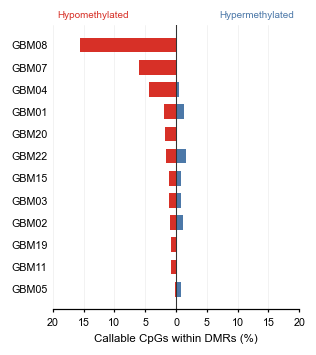

,GBM,sample,callable_cpgs,hypo_cpgs,hyper_cpgs,hypo_pct_cpg,hyper_pct_cpg
11,GBM08,UM159,14277,2218,24,15.535477,0.168103
10,GBM07,UM146,17832,1071,17,6.006057,0.095334
9,GBM04,UM130,19699,867,95,4.401239,0.482258
8,GBM01,UM029,45376,848,565,1.868829,1.245152
7,GBM20,UM244,12372,212,4,1.713547,0.032331
6,GBM22,UM258,25002,402,403,1.607871,1.611871
5,GBM15,UM215,12556,139,92,1.107040,0.732717
4,GBM03,UM124,21201,228,171,1.075421,0.806566
3,GBM02,UM116,21638,217,229,1.002865,1.058323
2,GBM19,UM233,9237,82,4,0.887734,0.043304


Saved: ecDNA_meth/clean_dss_results/figures_v4/DMR_fraction_callable_CpGs_GBMIDs.png


In [22]:
# ============================================================
# Callable-CpG DMR burden plot (Figure 5B)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

HYPO, HYPER, DARK = "#D73027", "#4C78A8", "#333333"

p = cpg_burden.copy()
p["GBM"] = p["sample"].map(GBM_ID)

# strongest hypomethylation at top
p = p.sort_values(
    ["hypo_pct_cpg", "hyper_pct_cpg"],
    ascending=[True, False]
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(2.8, 3.15))
y = np.arange(len(p))

ax.barh(y, -p["hypo_pct_cpg"], height=.66,
        color=HYPO, edgecolor="none")
ax.barh(y,  p["hyper_pct_cpg"], height=.66,
        color=HYPER, edgecolor="none")

ax.axvline(0, color=DARK, lw=.7)

ax.set_yticks(y)
ax.set_yticklabels(p["GBM"], fontsize=7)

m = max(p["hypo_pct_cpg"].max(), p["hyper_pct_cpg"].max())
step = 5
lim = np.ceil(m/step)*step
ticks = np.arange(-lim, lim+step, step)

ax.set_xlim(-lim, lim)
ax.set_xticks(ticks)
ax.set_xticklabels([f"{abs(x):g}" for x in ticks], fontsize=7)

ax.set_xlabel("Callable CpGs within DMRs (%)", fontsize=7.5)

ax.text(.02, 1.025, "Hypomethylated",
        transform=ax.transAxes, ha="left",
        fontsize=6.5, color=HYPO)

ax.text(.98, 1.025, "Hypermethylated",
        transform=ax.transAxes, ha="right",
        fontsize=6.5, color=HYPER)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", lw=.4, alpha=.25)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=2)


plt.tight_layout(pad=.5)

out = OUT_ROOT / "figures_v4" / "DMR_fraction_callable_CpGs_GBMIDs.png"
out.parent.mkdir(parents=True, exist_ok=True)

#plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

display(
    p[["GBM","sample","callable_cpgs",
       "hypo_cpgs","hyper_cpgs",
       "hypo_pct_cpg","hyper_pct_cpg"]]
    .sort_values("hypo_pct_cpg", ascending=False)
)

print("Saved:", out)

## 8. Figure 5C: haplotype-specific methylation profile of each tumor

For every tumor: methylation of the **chromosomal** haplotype is plotted upward and of the **amplified** haplotype
downward. Dots are raw per-CpG methylation; lines are DSS's smoothed estimates. The lower panel shows the effect size of
every DMR, with the amplified interval and *EGFR* marked. Figure 5C is the profile of GBM08 (`UM159`); the other tumors are
shown for completeness.

[UM116/chr7_EGFR] >=8x: amp 24978/25909, chr 24065/25373
[UM116/chr7_EGFR] saved -> ecDNA_meth/clean_dss_results/figures_v4/UM116_chr7_EGFR_Tumor_20pct_stacked.png (20 DMRs)
[UM124/chr7_EGFR] >=8x: amp 26095/26116, chr 23233/25660
[UM124/chr7_EGFR] saved -> ecDNA_meth/clean_dss_results/figures_v4/UM124_chr7_EGFR_Tumor_20pct_stacked.png (20 DMRs)
[UM130/chr7_EGFR] >=8x: amp 24311/24371, chr 21592/24398
[UM130/chr7_EGFR] saved -> ecDNA_meth/clean_dss_results/figures_v4/UM130_chr7_EGFR_Tumor_20pct_stacked.png (48 DMRs)
[UM137/chr7_EGFR] >=8x: amp 36874/38004, chr 28877/37361
[UM137/chr7_EGFR] saved -> ecDNA_meth/clean_dss_results/figures_v4/UM137_chr7_EGFR_Tumor_20pct_stacked.png (30 DMRs)
[UM146/chr7_EGFR] >=8x: amp 21649/21677, chr 20001/21506
[UM146/chr7_EGFR] saved -> ecDNA_meth/clean_dss_results/figures_v4/UM146_chr7_EGFR_Tumor_20pct_stacked.png (74 DMRs)
[UM159/chr7_EGFR] >=8x: amp 19097/19219, chr 17047/19416
[UM159/chr7_EGFR] saved -> ecDNA_meth/clean_dss_results/figures_v4/UM159_

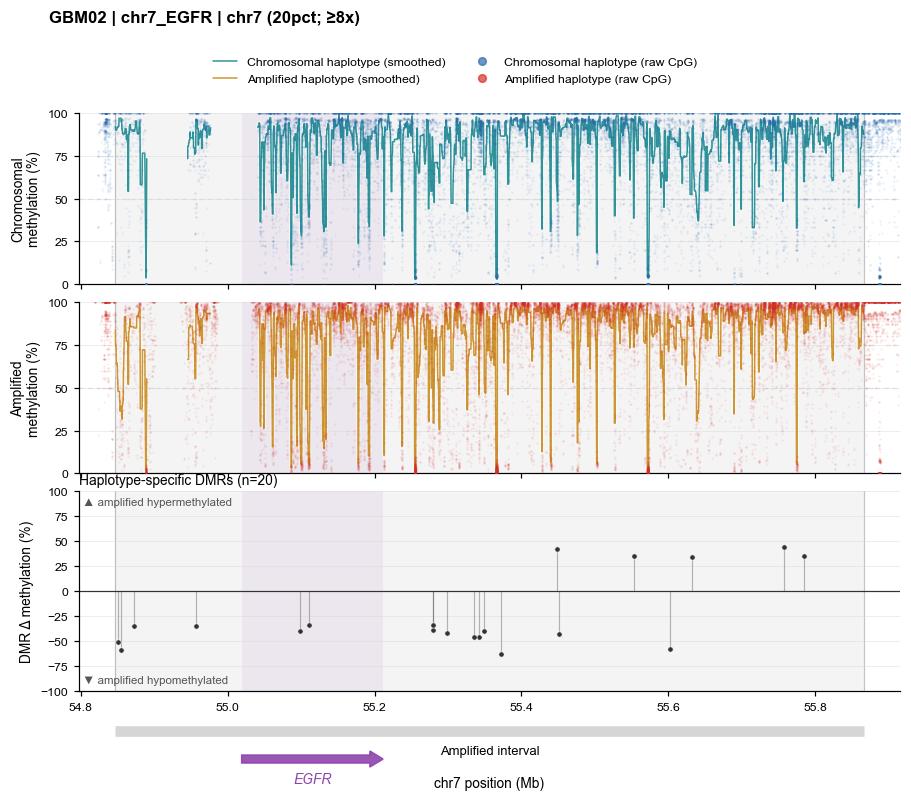

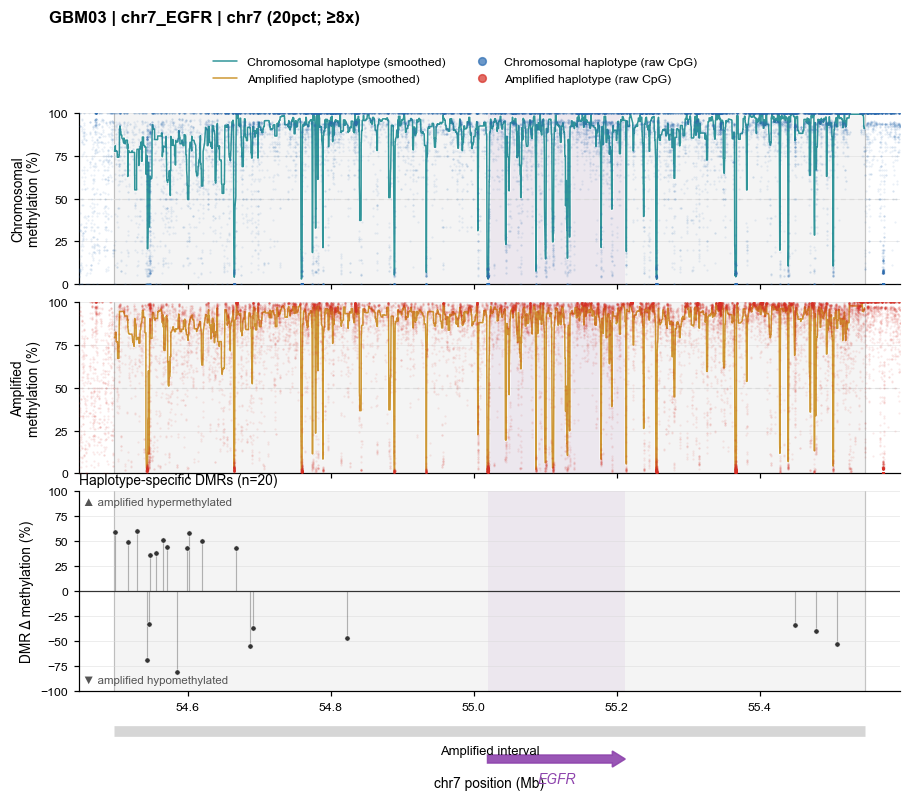

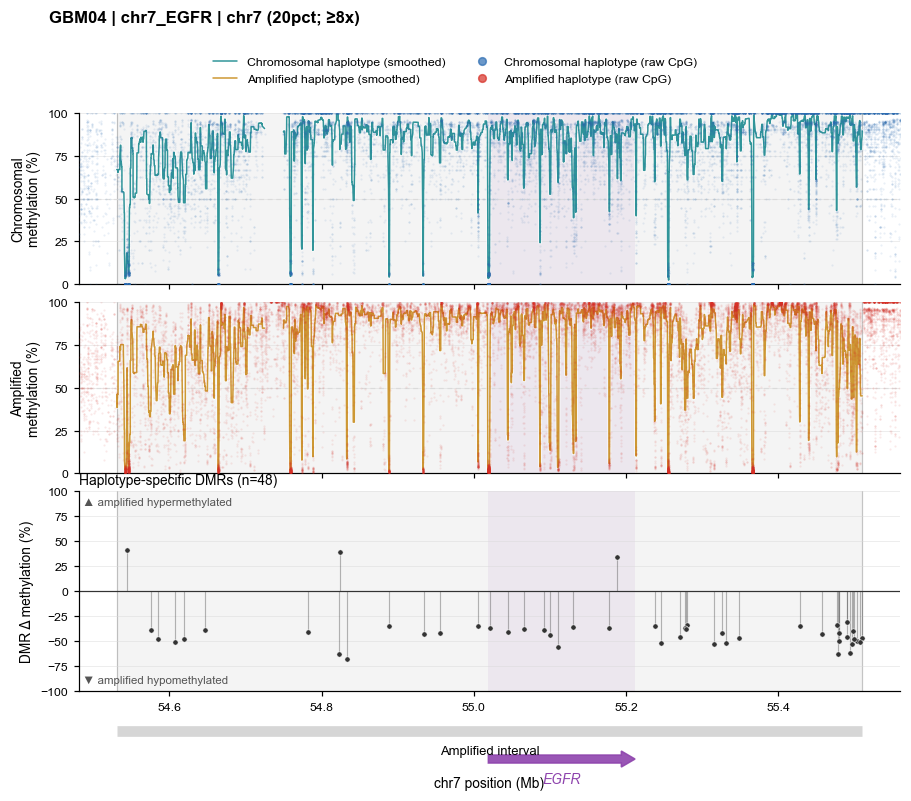

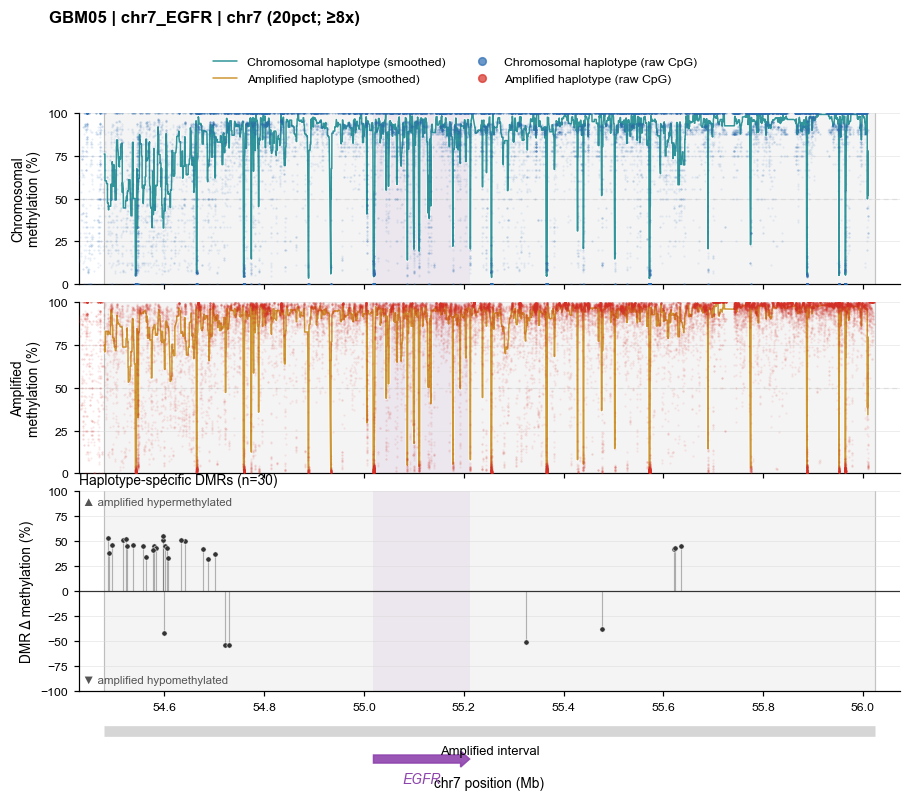

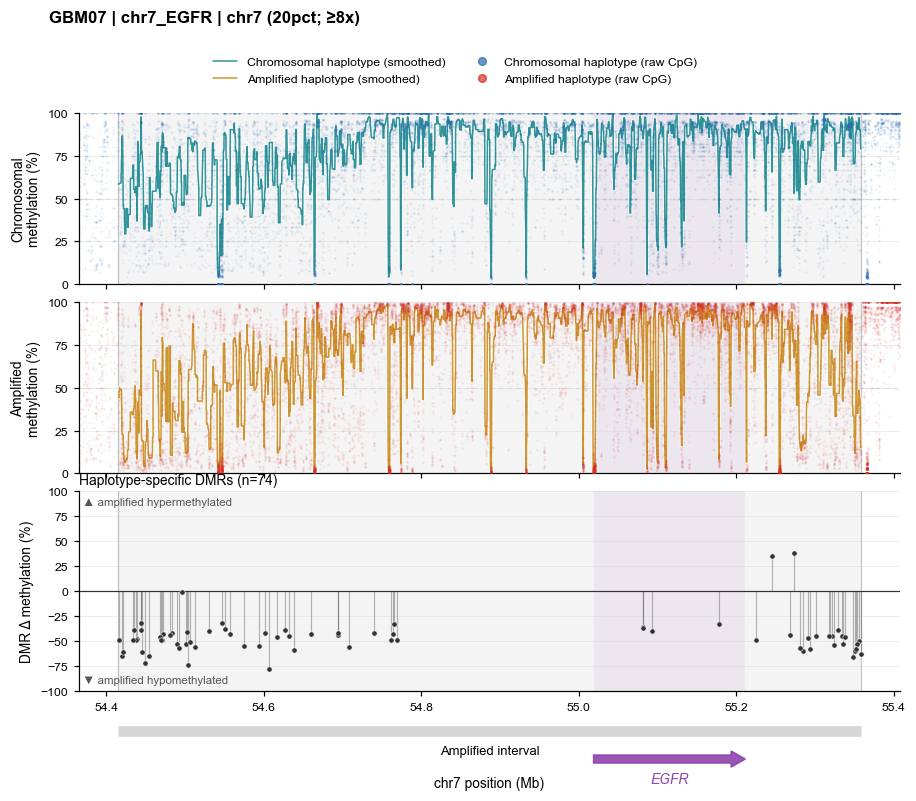

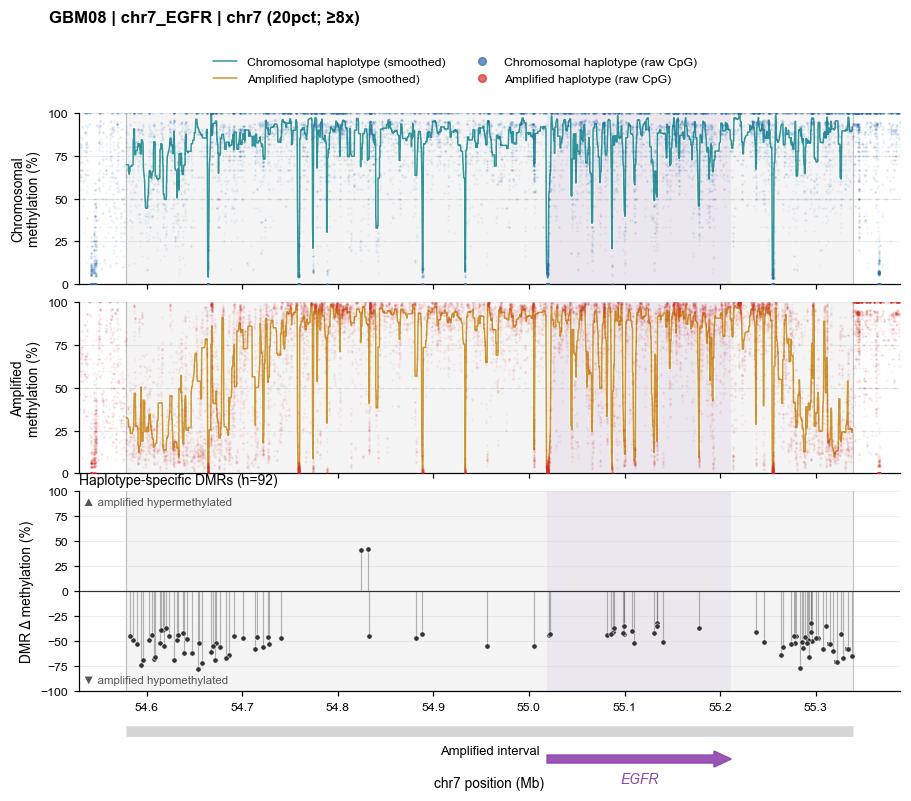

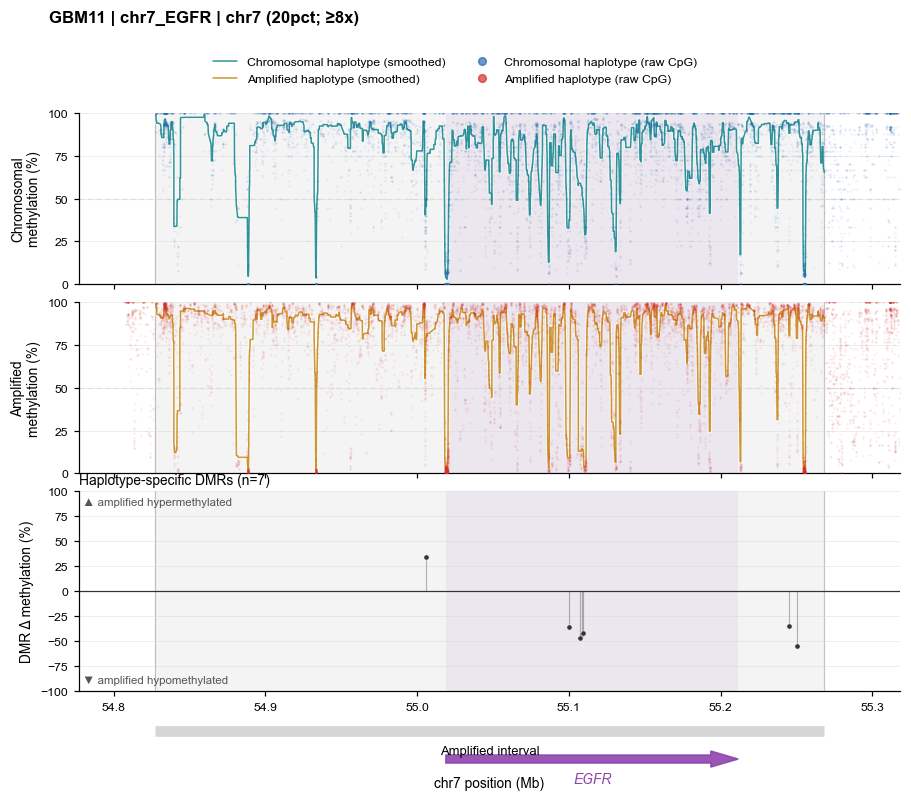

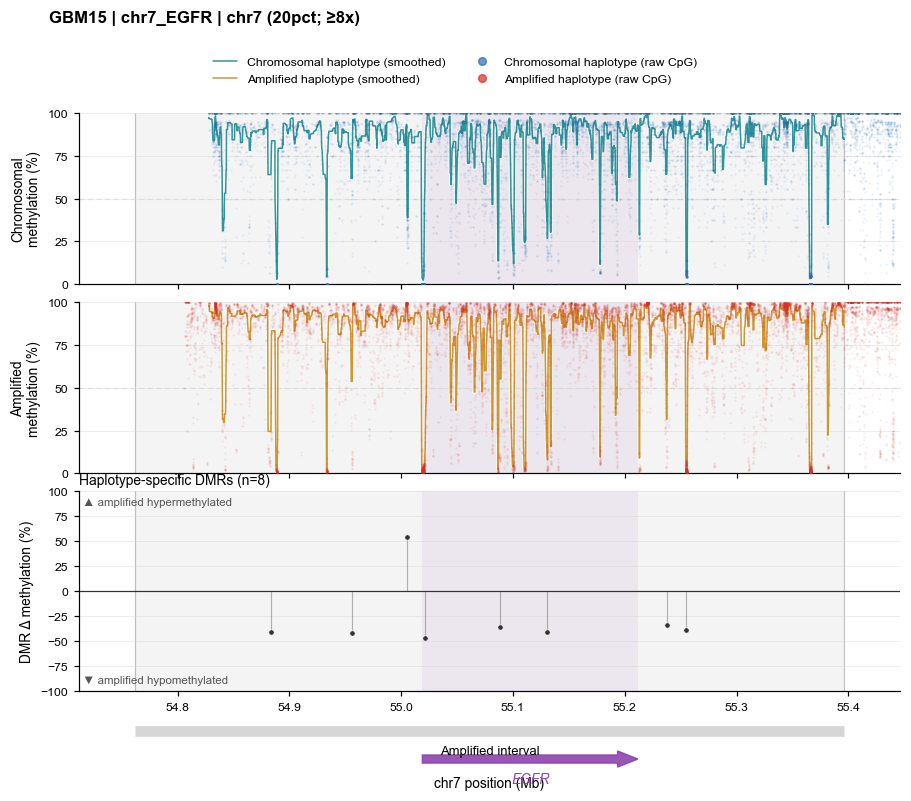

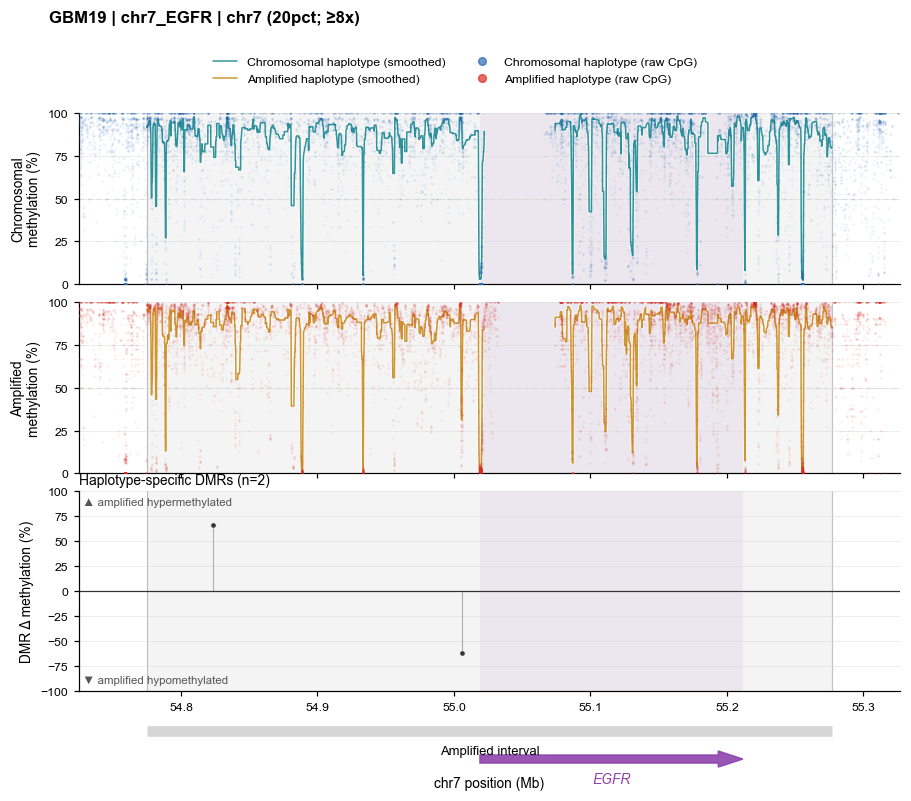

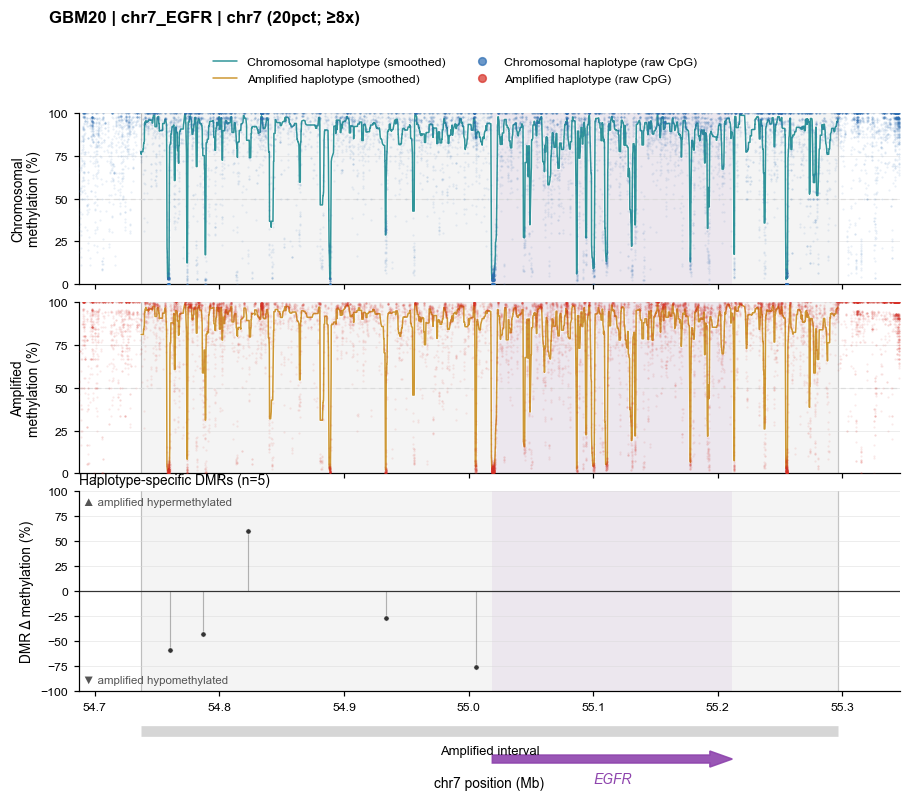

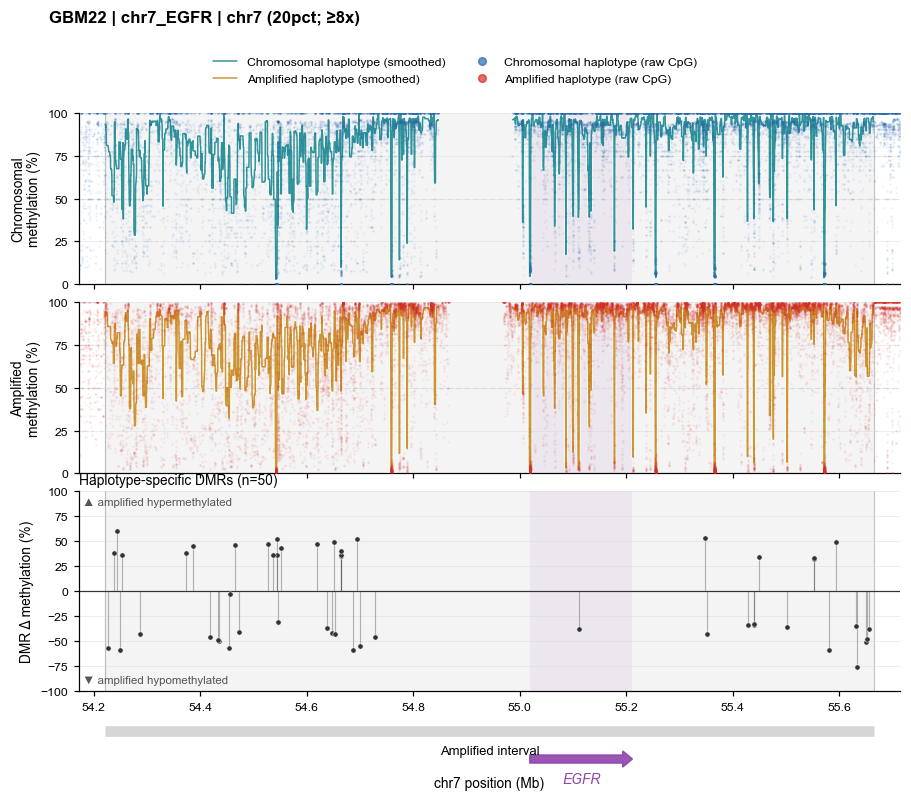

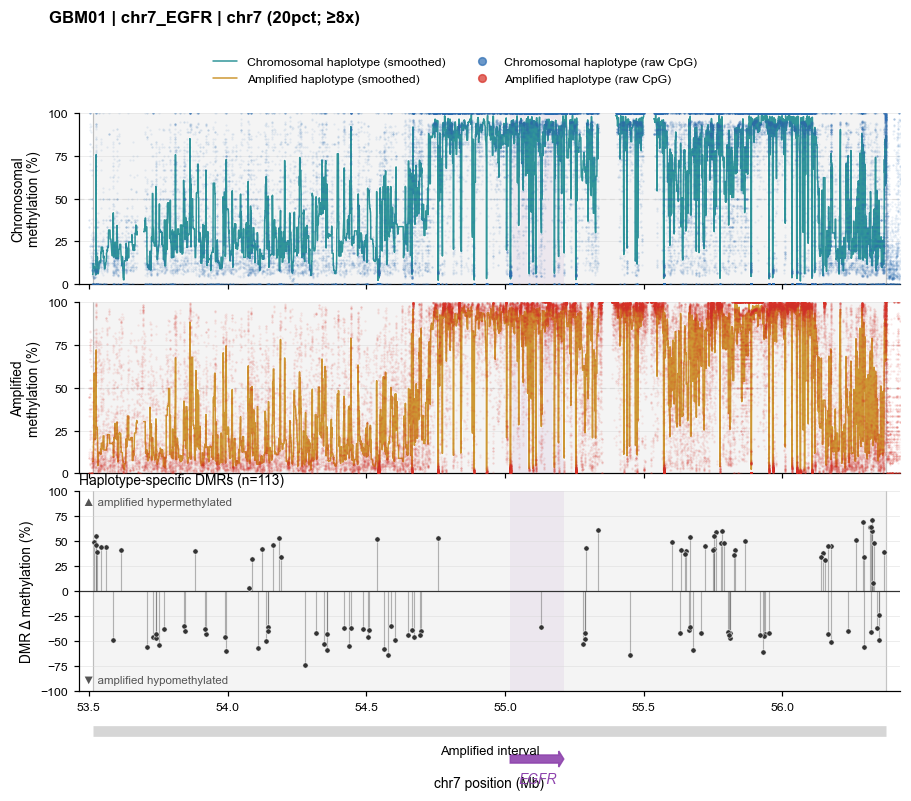

In [23]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrow

GRAY,LGRAY="#8A8A8A","#D9D9D9"
fig_dir=OUT_ROOT/"figures_v4"; fig_dir.mkdir(parents=True,exist_ok=True)
threshold_label=DSS_THRESHOLD; min_plot_coverage=MIN_SITE_COVERAGE; flank_pad_bp=50_000

def _classify_fallback(tumor_full,chrom,start,end):
    out={}
    for ps,df in tumor_full[tumor_full["chrom"]==chrom].groupby("ps"):
        x=df[df["pos"].between(start,end)].groupby("hp")["N"].sum()
        if len(x)<2 or x.sum()<MIN_TOTAL_COV_FOR_CLASSIFICATION: continue
        x=x.sort_values(ascending=False); hi,lo=float(x.iloc[0]),max(float(x.iloc[1]),1e-9)
        if hi/lo<MIN_COV_RATIO: continue
        out[ps]={"amp_hp":int(x.index[0]),"other_hp":int(x.index[1])}
    return out

def _halo(ax,x,y,c,label):
    l,=ax.plot(x,y,color=c,lw=1,alpha=.9,label=label,zorder=3,solid_capstyle="round")
    l.set_path_effects([pe.Stroke(linewidth=2.3,foreground="white",alpha=.6),pe.Normal()])
    return l

def _clean(ax):
    ax.spines[["top","right"]].set_visible(False)
    ax.grid(axis="y",color=LGRAY,lw=.6,alpha=.5)

def plot_one(sample,locus_name,chrom,amp_start,amp_end,tissue="Tumor"):
    so=OUT_ROOT/sample; pre=f"{sample}_{locus_name}_{tissue}_{threshold_label}"
    dmr_csv=so/f"{pre}_dmrs.csv"; per_csv=so/f"{pre}_persite.csv"
    if not dmr_csv.exists() or not per_csv.exists():
        print(f"[{sample}/{locus_name}] missing DSS output"); return

    dmrs=pd.read_csv(dmr_csv); pf=pd.read_csv(per_csv).sort_values("pos")
    cls=CLASSIFICATION.get((sample,locus_name),{}) if "CLASSIFICATION" in globals() else {}
    if not cls:
        f=DATA_DIR/f"{sample}_Tumor_master_cpg_table.csv.gz"
        tf=pd.read_csv(f); cls=_classify_fallback(tf[tf["threshold"]=="none"],chrom,amp_start,amp_end)
    if not cls:
        print(f"[{sample}/{locus_name}] no classification"); return

    xmin,xmax=amp_start-flank_pad_bp,amp_end+flank_pad_bp
    m=pd.read_csv(DATA_DIR/f"{sample}_{tissue}_master_cpg_table.csv.gz")
    w=m[(m["threshold"]==threshold_label)&(m["chrom"]==chrom)&m["pos"].between(xmin,xmax)&m["ps"].isin(cls)]

    A,O=[],[]
    for ps,df in w.groupby("ps"):
        z=cls[ps]
        A.append(df[df["hp"]==z["amp_hp"]][["pos","N","X"]])
        O.append(df[df["hp"]==z["other_hp"]][["pos","N","X"]])
    if not A or not O:
        print(f"[{sample}/{locus_name}] no phased CpGs"); return

    amp=pd.concat(A).groupby("pos",as_index=False).sum().sort_values("pos")
    oth=pd.concat(O).groupby("pos",as_index=False).sum().sort_values("pos")
    amp["pct"]=100*amp["X"]/amp["N"]; oth["pct"]=100*oth["X"]/oth["N"]
    na,no=len(amp),len(oth)
    amp=amp[amp["N"]>=min_plot_coverage]; oth=oth[oth["N"]>=min_plot_coverage]
    print(f"[{sample}/{locus_name}] >={min_plot_coverage}x: amp {len(amp)}/{na}, chr {len(oth)}/{no}")

    p=pf[pf["pos"].between(xmin,xmax)].copy()
    p["mu1_vis"]=(p["mu1"]*100).rolling(41,center=True,min_periods=5).median().fillna(p["mu1"]*100)
    p["mu2_vis"]=(p["mu2"]*100).rolling(41,center=True,min_periods=5).median().fillna(p["mu2"]*100)
    p.loc[p["pos"].diff()>20_000,["mu1_vis","mu2_vis"]]=np.nan

    d=dmrs[(dmrs["end"]>=xmin)&(dmrs["start"]<=xmax)].copy()
    d["mid"]=(d["start"]+d["end"])/2; d["effect_pp"]=d["diff.Methy"]*100
    egfr="EGFR" in locus_name

    fig,(cx,ax,dx)=plt.subplots(3,1,figsize=(9,7.2),sharex=True,
        gridspec_kw={"height_ratios":[1.2,1.2,1.4],"hspace":.10})

    def marks(q):
        q.axvspan(amp_start/1e6,amp_end/1e6,color=GRAY,alpha=.09,lw=0,zorder=0)
        for x in [amp_start,amp_end]: q.axvline(x/1e6,color=GRAY,lw=.8,alpha=.5,zorder=0)
        if egfr: q.axvspan(EGFR_START/1e6,EGFR_END/1e6,color=EGFR_C,alpha=.07,lw=0,zorder=0)

    marks(cx)
    l2=_halo(cx,p["pos"]/1e6,p["mu2_vis"],"#1B8A8F","Chromosomal haplotype (smoothed)")
    cx.scatter(oth["pos"]/1e6,oth["pct"],s=2,color=OTHER,alpha=.1,lw=0,rasterized=True,zorder=5)
    cx.set_ylim(0,100); cx.set_yticks([0,25,50,75,100]); cx.set_ylabel("Chromosomal\nmethylation (%)")
    cx.axhline(50,color=LGRAY,lw=.8,ls=(0,(4,3)),alpha=.8); _clean(cx)

    marks(ax)
    l1=_halo(ax,p["pos"]/1e6,p["mu1_vis"],"#C98D1E","Amplified haplotype (smoothed)")
    ax.scatter(amp["pos"]/1e6,amp["pct"],s=2,color=AMP,alpha=.1,lw=0,rasterized=True,zorder=5)
    ax.set_ylim(0,100); ax.set_yticks([0,25,50,75,100]); ax.set_ylabel("Amplified\nmethylation (%)")
    ax.axhline(50,color=LGRAY,lw=.8,ls=(0,(4,3)),alpha=.8); _clean(ax)

    marks(dx); dx.axhline(0,color=DARK,lw=.8)
    for _,r in d.iterrows():
        m,s,e=r["mid"]/1e6,r["start"]/1e6,r["end"]/1e6
        dx.vlines(m,0,r["effect_pp"],color=DARK,lw=.75,alpha=.35)
        dx.hlines(r["effect_pp"],s,e,color=DARK,lw=2.4,alpha=.85)
        dx.scatter(m,r["effect_pp"],s=12,color=DARK,edgecolor="white",lw=.35,zorder=3)

    dx.set_ylim(-100,100); dx.set_ylabel("DMR Δ methylation (%)")
    dx.set_title(f"Haplotype-specific DMRs (n={len(d)})",loc="left",fontsize=9,pad=5)
    dx.text(.005,.97,"▲ amplified hypermethylated",transform=dx.transAxes,fontsize=7.5,color="#555",va="top")
    dx.text(.005,.03,"▼ amplified hypomethylated",transform=dx.transAxes,fontsize=7.5,color="#555",va="bottom")
    _clean(dx)

    tr=dx.get_xaxis_transform(); s,e=amp_start/1e6,amp_end/1e6
    dx.plot([s,e],[-.20,-.20],transform=tr,color=GRAY,lw=7,alpha=.35,solid_capstyle="butt",clip_on=False)
    dx.text((s+e)/2,-.30,"Amplified interval",transform=tr,ha="center",va="center",fontsize=8.5,clip_on=False)

    if egfr:
        gs,ge=EGFR_START/1e6,EGFR_END/1e6
        st,dd=(ge,gs-ge) if EGFR_STRAND=="-" else (gs,ge-gs)
        dx.add_patch(FancyArrow(st,-.34,dd,0,width=.04,head_width=.08,head_length=.018,
            length_includes_head=True,color=EGFR_C,alpha=.9,transform=tr,clip_on=False))
        dx.text((gs+ge)/2,-.44,"EGFR",transform=tr,ha="center",va="center",
            fontsize=9,color=EGFR_C,fontstyle="italic",clip_on=False)

    for q in [cx,ax,dx]: q.set_xlim(xmin/1e6,xmax/1e6)
    dx.set_xlabel(f"{chrom} position (Mb)",labelpad=42 if egfr else 8)

    fig.suptitle(f"{GBM_ID.get(sample, sample)} | {locus_name} | {chrom} ({threshold_label}; ≥{min_plot_coverage}x)",
        x=.09,y=1.01,ha="left",fontweight="bold",fontsize=11)

    fig.legend(handles=[
        l2,l1,
        Line2D([0],[0],marker="o",ls="None",color=OTHER,markersize=5,alpha=.7,label="Chromosomal haplotype (raw CpG)"),
        Line2D([0],[0],marker="o",ls="None",color=AMP,markersize=5,alpha=.7,label="Amplified haplotype (raw CpG)")
    ],loc="upper center",ncol=2,frameon=False,bbox_to_anchor=(.5,.965),fontsize=8)

    plt.subplots_adjust(left=.12,right=.95,top=.88,bottom=.15 if egfr else .09)
    out=fig_dir/f"{sample}_{locus_name}_{tissue}_{threshold_label}_stacked.png"
    plt.savefig(out,dpi=250,bbox_inches="tight",facecolor="white"); display(fig); plt.close(fig)
    print(f"[{sample}/{locus_name}] saved -> {out} ({len(d)} DMRs)")

samples=METHYLATION_SAMPLES if "METHYLATION_SAMPLES" in globals() else MAIN_EGFR_SAMPLES
for sample in samples:
    x=[l for l in SAMPLE_LOCI[sample] if l[0]=="chr7_EGFR"]
    if not x: continue
    locus,chrom,start,end=x[0]
    plot_one(sample,locus,chrom,start,end)

print(f"\nAll figures in: {fig_dir}")

## 9. Figure 5D: recurrent DMRs

DMRs from different tumors that overlap are merged into a cluster. For each cluster we record how many tumors share it
(`n_samples`) and, separately, in how many tumors the interval was actually **testable** (`n_tested_here`): a tumor counts
as testable only if at least 3 jointly callable CpGs fall inside the interval. This matters because a region can only be
"recurrent" in tumors that had the coverage to detect a DMR there. Clusters are annotated against ENCODE cCREs and published
EGFR regulatory elements (Hoogstrate et al. 2022; Jameson et al. 2019; Tang et al. 2025; Sankar et al. 2026).

The cCRE files are the ENCODE registry of candidate cis-regulatory elements (hg38) restricted to chr7:49-59 Mb
(`ccre_chr7_49_59Mb.bed`) and chr7:22-24 Mb (`ccre_chr7_22_24Mb.bed`, the partner segment of GBM15).

In [24]:
# ============================================================
# RECURRENT DMRs + ACTUAL CALLABILITY + REGULATORY ANNOTATION
# ============================================================

CE1=("chr7",55_060_994,55_066_815)
CE2=("chr7",55_127_646,55_135_347)
TANG_REGION=("chr7",55_109_000,55_112_000)

SANKAR_RE_HG38={
    "GBM39_raw_hit_1":("chr7",55_019_308,55_020_307),
    "GBM39_raw_hit_2":("chr7",55_365_308,55_366_307),
    "RE-A":("chr7",55_254_266,55_255_787),
    "RE-B":("chr7",55_365_155,55_367_161),
    "RE-D":("chr7",55_964_516,55_965_696),
    "RE-E":("chr7",55_018_783,55_020_570),
    "RE-F":("chr7",55_571_369,55_572_685),
}

CCRE_COLS=["chrom","start","end","name","score","strand","thickStart","thickEnd",
           "itemRgb","ucscLabel","score1","score2","score3","score4"]
ccre_frames=[]
for bf in [DATA_DIR/"ccre_chr7_49_59Mb.bed",DATA_DIR/"ccre_chr7_22_24Mb.bed"]:
    if bf.exists():
        x=pd.read_csv(bf,sep="\t",header=None)
        x.columns=CCRE_COLS[:x.shape[1]] if x.shape[1]<=len(CCRE_COLS) else CCRE_COLS+[f"extra_{i}" for i in range(x.shape[1]-len(CCRE_COLS))]
        ccre_frames.append(x)
ccre=pd.concat(ccre_frames,ignore_index=True) if ccre_frames else pd.DataFrame(columns=CCRE_COLS)

def overlaps(a0,a1,b0,b1): return a0<b1 and b0<a1

def annotate_cluster(start,end,chrom="chr7"):
    h=ccre[(ccre["chrom"]==chrom)&(ccre["start"]<end)&(start<ccre["end"])]
    sank=[n for n,(c,s,e) in SANKAR_RE_HG38.items() if c==chrom and overlaps(start,end,s,e)]
    return {
        "n_ccres":len(h),
        "ccre_types":"; ".join(sorted(h["ucscLabel"].dropna().astype(str).unique())) if len(h) else None,
        "overlaps_CE1":overlaps(start,end,CE1[1],CE1[2]),
        "overlaps_CE2":overlaps(start,end,CE2[1],CE2[2]),
        "overlaps_Tang2025":overlaps(start,end,TANG_REGION[1],TANG_REGION[2]),
        "overlaps_Sankar_RE":"; ".join(sank) if sank else None
    }

def merge_cross_sample_dmrs(df):
    if df.empty: return []
    ivs=df[["start","end","sample","diff_methy_pp"]].sort_values(["start","end"]).to_dict("records")
    out=[]; cur=None
    for iv in ivs:
        if cur is None: cur={"start":int(iv["start"]),"end":int(iv["end"]),"members":[iv]}; continue
        if int(iv["start"])<=cur["end"]:
            cur["end"]=max(cur["end"],int(iv["end"])); cur["members"].append(iv)
        else:
            out.append(cur); cur={"start":int(iv["start"]),"end":int(iv["end"]),"members":[iv]}
    if cur: out.append(cur)
    return out

def recurrence_callability(start,end,locus_name="chr7_EGFR"):
    tested=[]; counts={}
    samples=METHYLATION_SAMPLES if "METHYLATION_SAMPLES" in globals() else MAIN_EGFR_SAMPLES
    for sample in samples:
        so=OUT_ROOT/sample; pre=f"{sample}_{locus_name}_Tumor_{DSS_THRESHOLD}"
        a=so/f"{pre}_dmrs_amp.csv"; o=so/f"{pre}_dmrs_other.csv"
        if not a.exists() or not o.exists(): continue
        A=pd.read_csv(a,usecols=["pos"]); O=pd.read_csv(o,usecols=["pos"])
        n=A[A["pos"].between(start,end)][["pos"]].merge(
            O[O["pos"].between(start,end)][["pos"]],on="pos",how="inner"
        )["pos"].nunique()
        counts[sample]=int(n)
        if n>=MIN_CPGS_TO_COUNT_AS_TESTABLE: tested.append(sample)
    return tested,counts

def build_recurrent_clusters(dmr_support,direction,min_samples=MIN_RECURRENCE_SAMPLES):
    rows=[]
    sub=dmr_support[dmr_support["direction"]==direction]
    for c in merge_cross_sample_dmrs(sub):
        member_samples=sorted({m["sample"] for m in c["members"]})
        if len(member_samples)<min_samples: continue
        tested,ncpg=recurrence_callability(c["start"],c["end"])
        effects=[float(m["diff_methy_pp"]) for m in c["members"]]
        rows.append({
            "start":c["start"],"end":c["end"],"mid":(c["start"]+c["end"])/2,
            "direction":direction,"n_samples":len(member_samples),
            "samples":"; ".join(member_samples),
            "n_tested_here":len(tested),"tested_samples":"; ".join(tested),
            "recurrence_rate":len(member_samples)/len(tested) if tested else np.nan,
            "mean_effect_pp":np.mean(effects),"median_effect_pp":np.median(effects),
            "n_dmrs_merged":len(c["members"]),
            "cpg_callability_by_sample":"; ".join(f"{s}:{n}" for s,n in sorted(ncpg.items())),
            **annotate_cluster(c["start"],c["end"])
        })
    return pd.DataFrame(rows)

if len(dmr_support):
    recurrent_hypo=build_recurrent_clusters(dmr_support,"hypo")
    recurrent_hyper=build_recurrent_clusters(dmr_support,"hyper")

    recurrent_hypo.to_csv(OUT_ROOT/"recurrent_hypomethylated_clusters_annotated.csv",index=False)
    recurrent_hyper.to_csv(OUT_ROOT/"recurrent_hypermethylated_clusters_annotated.csv",index=False)

    print("HYPO")
    display(recurrent_hypo.sort_values(["n_samples","n_tested_here"],ascending=False).head(10))

    print("HYPER")
    if len(recurrent_hyper):
        display(recurrent_hyper.sort_values(["n_samples","n_tested_here"],ascending=False).head(5))
    else:
        print("no hypermethylated interval is shared by >= %d tumors" % MIN_RECURRENCE_SAMPLES)

HYPO


,start,end,mid,direction,n_samples,samples,n_tested_here,tested_samples,recurrence_rate,mean_effect_pp,median_effect_pp,n_dmrs_merged,cpg_callability_by_sample,n_ccres,ccre_types,overlaps_CE1,overlaps_CE2,overlaps_Tang2025,overlaps_Sankar_RE
31,55109374,55111363,55110368.5,hypo,5,UM116; UM130; UM159; UM170; UM258,12,UM116; UM124; UM130; UM137; UM146; UM159; UM17...,0.416667,-44.438013,-42.088179,5,UM029:63; UM116:66; UM124:66; UM130:66; UM137:...,6,Distal enhancer,False,False,True,None
24,54955855,54956313,54956084.0,hypo,4,UM116; UM130; UM159; UM215,11,UM116; UM124; UM130; UM137; UM146; UM159; UM17...,0.363636,-43.223776,-41.724974,4,UM029:15; UM116:16; UM124:9; UM130:16; UM137:1...,2,Distal enhancer,False,False,False,None
25,55005027,55006164,55005595.5,hypo,4,UM130; UM159; UM233; UM244,11,UM124; UM130; UM137; UM146; UM159; UM170; UM21...,0.363636,-56.890878,-58.255366,4,UM029:95; UM116:0; UM124:57; UM130:96; UM137:9...,2,CA-H3K4me3,False,False,False,None
48,55330753,55337066,55333909.5,hypo,4,UM116; UM130; UM146; UM159,9,UM116; UM124; UM130; UM137; UM146; UM159; UM21...,0.444444,-50.616757,-51.596919,5,UM029:118; UM116:128; UM124:133; UM130:142; UM...,4,CA; Distal enhancer,False,False,False,None
29,55098910,55100957,55099933.5,hypo,3,UM130; UM159; UM170,12,UM116; UM124; UM130; UM137; UM146; UM159; UM17...,0.250000,-39.291044,-39.206549,4,UM029:64; UM116:64; UM124:58; UM130:60; UM137:...,6,Distal enhancer,False,False,False,None
32,55130010,55130982,55130496.0,hypo,3,UM130; UM159; UM215,12,UM116; UM124; UM130; UM137; UM146; UM159; UM17...,0.250000,-39.619973,-41.251038,3,UM029:40; UM116:40; UM124:40; UM130:40; UM137:...,4,Distal enhancer,False,True,False,None
33,55177568,55178099,55177833.5,hypo,3,UM130; UM146; UM159,12,UM116; UM124; UM130; UM137; UM146; UM159; UM17...,0.250000,-35.494456,-36.407169,3,UM029:38; UM116:38; UM124:38; UM130:36; UM137:...,1,Distal enhancer,False,False,False,None
34,55237222,55237688,55237455.0,hypo,3,UM130; UM159; UM215,12,UM116; UM124; UM130; UM137; UM146; UM159; UM17...,0.250000,-36.500058,-35.055416,3,UM029:12; UM116:20; UM124:20; UM130:20; UM137:...,1,Distal enhancer,False,False,False,None
35,55245276,55245845,55245560.5,hypo,3,UM130; UM159; UM170,12,UM116; UM124; UM130; UM137; UM146; UM159; UM17...,0.250000,-45.731153,-50.586425,3,UM029:25; UM116:24; UM124:17; UM130:24; UM137:...,1,Proximal enhancer,False,False,False,None
26,55020593,55022454,55021523.5,hypo,3,UM130; UM159; UM215,11,UM124; UM130; UM137; UM146; UM159; UM170; UM21...,0.272727,-42.791245,-43.458780,4,UM029:74; UM116:0; UM124:75; UM130:74; UM137:7...,6,Distal enhancer; Proximal enhancer,False,False,False,None


HYPER


,start,end,mid,direction,n_samples,samples,n_tested_here,tested_samples,recurrence_rate,mean_effect_pp,median_effect_pp,n_dmrs_merged,cpg_callability_by_sample,n_ccres,ccre_types,overlaps_CE1,overlaps_CE2,overlaps_Tang2025,overlaps_Sankar_RE
4,55005149,55006164,55005656.5,hyper,2,UM170; UM215,11,UM124; UM130; UM137; UM146; UM159; UM170; UM21...,0.181818,44.154057,44.154057,2,UM029:91; UM116:0; UM124:53; UM130:92; UM137:9...,2,CA-H3K4me3,False,False,False,None
3,54823799,54824046,54823922.5,hyper,2,UM130; UM159,9,UM124; UM130; UM137; UM146; UM159; UM233; UM24...,0.222222,40.427392,40.427392,2,UM029:9; UM116:0; UM124:10; UM130:9; UM137:10;...,1,Distal enhancer,False,False,False,None
1,54544491,54545287,54544889.0,hyper,2,UM130; UM258,6,UM124; UM130; UM137; UM146; UM258; UM029,0.333333,38.747121,38.747121,2,UM029:98; UM116:0; UM124:96; UM130:98; UM137:9...,2,Distal enhancer,False,False,False,None
5,55448438,55449533,55448985.5,hyper,2,UM116; UM258,6,UM116; UM124; UM130; UM137; UM258; UM029,0.333333,38.461423,38.461423,2,UM029:130; UM116:156; UM124:156; UM130:156; UM...,2,CA-H3K4me3,False,False,False,None
0,54527883,54528127,54528005.0,hyper,2,UM124; UM258,5,UM124; UM137; UM146; UM258; UM029,0.400000,53.498040,53.498040,2,UM029:5; UM116:0; UM124:10; UM130:0; UM137:10;...,0,None,False,False,False,None


Clusters shared by at least 3 tumors and testable in at least 6 form the main set that is plotted and tested below.

In [31]:
MIN_TESTED_FOR_MAIN_PLOT = 6
MIN_RECURRENT_FOR_MAIN_PLOT = 3

if len(dmr_support):
    recurrent_all = pd.concat(
        [recurrent_hypo, recurrent_hyper],
        ignore_index=True
    )

    print("n_tested_here distribution")
    display(
        recurrent_all["n_tested_here"]
        .value_counts()
        .sort_index()
        .rename_axis("n_tested_here")
        .reset_index(name="n_clusters")
    )

    recurrence_plot_df = recurrent_all[
        (recurrent_all["n_tested_here"] >= MIN_TESTED_FOR_MAIN_PLOT)
        & (recurrent_all["n_samples"] >= MIN_RECURRENT_FOR_MAIN_PLOT)
    ].copy()

    print(
        f"{len(recurrence_plot_df)} / {len(recurrent_all)} recurrent clusters retained "
        f"with n_tested_here >= {MIN_TESTED_FOR_MAIN_PLOT} and "
        f"n_samples >= {MIN_RECURRENT_FOR_MAIN_PLOT}"
    )

    display(
        recurrence_plot_df.sort_values(
            ["n_samples", "n_tested_here"], ascending=False
        )
    )

n_tested_here distribution


,n_tested_here,n_clusters
0,3,5
1,4,5
2,5,5
3,6,9
4,7,9
5,8,1
6,9,7
7,10,7
8,11,6
9,12,9


16 / 63 recurrent clusters retained with n_tested_here >= 6 and n_samples >= 3


,start,end,mid,direction,n_samples,samples,n_tested_here,tested_samples,recurrence_rate,mean_effect_pp,median_effect_pp,n_dmrs_merged,cpg_callability_by_sample,n_ccres,ccre_types,overlaps_CE1,overlaps_CE2,overlaps_Tang2025,overlaps_Sankar_RE
31,55109374,55111363,55110368.5,hypo,5,UM116; UM130; UM159; UM170; UM258,12,UM116; UM124; UM130; UM137; UM146; UM159; UM17...,0.416667,-44.438013,-42.088179,5,UM029:63; UM116:66; UM124:66; UM130:66; UM137:...,6,Distal enhancer,False,False,True,None
24,54955855,54956313,54956084.0,hypo,4,UM116; UM130; UM159; UM215,11,UM116; UM124; UM130; UM137; UM146; UM159; UM17...,0.363636,-43.223776,-41.724974,4,UM029:15; UM116:16; UM124:9; UM130:16; UM137:1...,2,Distal enhancer,False,False,False,None
25,55005027,55006164,55005595.5,hypo,4,UM130; UM159; UM233; UM244,11,UM124; UM130; UM137; UM146; UM159; UM170; UM21...,0.363636,-56.890878,-58.255366,4,UM029:95; UM116:0; UM124:57; UM130:96; UM137:9...,2,CA-H3K4me3,False,False,False,None
48,55330753,55337066,55333909.5,hypo,4,UM116; UM130; UM146; UM159,9,UM116; UM124; UM130; UM137; UM146; UM159; UM21...,0.444444,-50.616757,-51.596919,5,UM029:118; UM116:128; UM124:133; UM130:142; UM...,4,CA; Distal enhancer,False,False,False,None
29,55098910,55100957,55099933.5,hypo,3,UM130; UM159; UM170,12,UM116; UM124; UM130; UM137; UM146; UM159; UM17...,0.250000,-39.291044,-39.206549,4,UM029:64; UM116:64; UM124:58; UM130:60; UM137:...,6,Distal enhancer,False,False,False,None
32,55130010,55130982,55130496.0,hypo,3,UM130; UM159; UM215,12,UM116; UM124; UM130; UM137; UM146; UM159; UM17...,0.250000,-39.619973,-41.251038,3,UM029:40; UM116:40; UM124:40; UM130:40; UM137:...,4,Distal enhancer,False,True,False,None
33,55177568,55178099,55177833.5,hypo,3,UM130; UM146; UM159,12,UM116; UM124; UM130; UM137; UM146; UM159; UM17...,0.250000,-35.494456,-36.407169,3,UM029:38; UM116:38; UM124:38; UM130:36; UM137:...,1,Distal enhancer,False,False,False,None
34,55237222,55237688,55237455.0,hypo,3,UM130; UM159; UM215,12,UM116; UM124; UM130; UM137; UM146; UM159; UM17...,0.250000,-36.500058,-35.055416,3,UM029:12; UM116:20; UM124:20; UM130:20; UM137:...,1,Distal enhancer,False,False,False,None
35,55245276,55245845,55245560.5,hypo,3,UM130; UM159; UM170,12,UM116; UM124; UM130; UM137; UM146; UM159; UM17...,0.250000,-45.731153,-50.586425,3,UM029:25; UM116:24; UM124:17; UM130:24; UM137:...,1,Proximal enhancer,False,False,False,None
26,55020593,55022454,55021523.5,hypo,3,UM130; UM159; UM215,11,UM124; UM130; UM137; UM146; UM159; UM170; UM21...,0.272727,-42.791245,-43.458780,4,UM029:74; UM116:0; UM124:75; UM130:74; UM137:7...,6,Distal enhancer; Proximal enhancer,False,False,False,None


**Brain H3K27ac.** A brain H3K27ac signal track (hg38 bigWig) is extracted for chr7:54-56 Mb on first use and then binned
to 50 bp. If the extracted bedGraph already exists, the bigWig is not needed.

In [27]:
H3K27AC_BIGWIG = DATA_DIR / "tpBrainH3K27ac.bw"                          # brain H3K27ac signal track (hg38)
H3K27AC_PATH = DATA_DIR / "tpBrainH3K27ac_chr7_54_56Mb.bedGraph"         # chr7:54-56 Mb extract

if not H3K27AC_PATH.exists():                                            # one-time extraction
    import pyBigWig
    bw = pyBigWig.open(str(H3K27AC_BIGWIG))
    h3 = pd.DataFrame(bw.intervals("chr7", 54_000_000, 56_000_000), columns=["start", "end", "signal"])
    h3.insert(0, "chrom", "chr7")
    h3.to_csv(H3K27AC_PATH, sep="\t", header=False, index=False)
    bw.close()

In [29]:
h3k27ac=pd.read_csv(
    H3K27AC_PATH,
    sep="\t",header=None,
    names=["chrom","start","end","signal"]
)

BIN=50

h3k27ac["bin"]=(h3k27ac["start"]//BIN)*BIN

h3k27ac_100bp=(
    h3k27ac.groupby("bin",as_index=False)
    .agg(signal=("signal","mean"))
)

h3k27ac_100bp["pos"]=h3k27ac_100bp["bin"]+BIN/2

print(h3k27ac_100bp.shape)

(40000, 3)


**Plot.** Each lollipop is a recurrent cluster at its mean effect size (percentage points, amplified minus chromosomal).
Below: published enhancers, a previously reported hypomethylated region, ecDNA retention elements, brain H3K27ac and gene models.

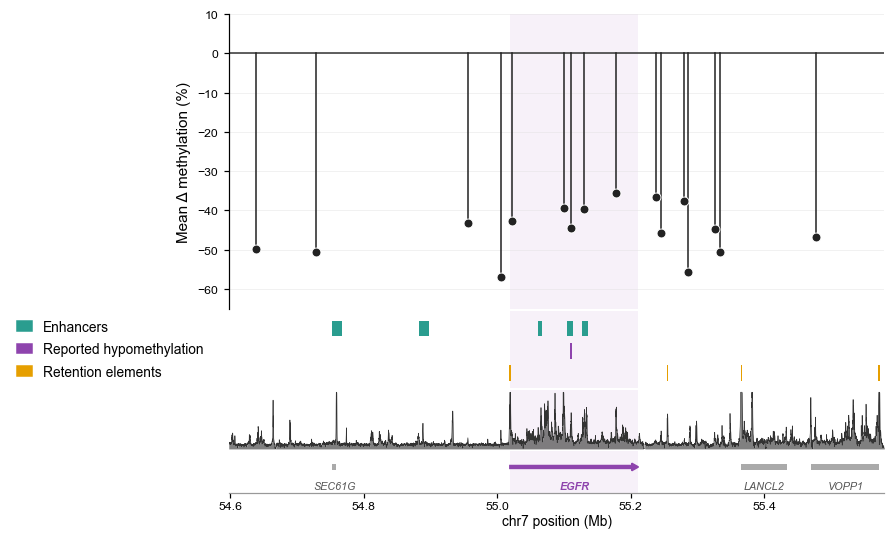

In [32]:
from matplotlib.patches import Rectangle, FancyArrow, Patch
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------------------------------
# Colors
# ---------------------------------------------------------------------

DMR_C = "#222"
GENE_GRAY = "#AAA"

ENHANCER_C = "#2A9D8F"
HYPOMETH_C = "#8E44AD"
RETENTION_C = "#E69F00"


# ---------------------------------------------------------------------
# Genomic annotations
# ---------------------------------------------------------------------

ALL_GENES = [
    ("VSTM2A", 54_542_375, 54_571_067, "+"),
    ("SEC61G", 54_752_253, 54_759_211, "-"),
    ("EGFR", EGFR_START, EGFR_END, EGFR_STRAND),
    ("LANCL2", 55_365_337, 55_433_737, "-"),
    ("VOPP1", 55_470_613, 55_572_502, "-"),
]

# Previously characterized enhancers
# Hoogstrate et al. 2022
HOOG = {
    "E4": (54_752_307, 54_767_307),
    "E1": (54_882_307, 54_897_307),
    "E3": (55_104_307, 55_114_307),
}

# Jameson et al. 2019
JAMESON = {
    "CE1": (55_060_994, 55_066_815),
    "CE2": (55_127_646, 55_135_347),
}

# Combine both studies into one biological annotation category
ENHANCERS = {
    **HOOG,
    **JAMESON,
}

# Previously reported hypomethylated region
# Tang et al. 2025
HYPOMETHYLATED_REGION = {
    "Tang": (55_109_000, 55_112_000),
}

# ecDNA retention elements
# Sankar et al. 2026
RETENTION_ELEMENTS = {
    "RE-A": (55_254_266, 55_255_787),
    "RE-B": (55_365_155, 55_367_161),
    "RE-D": (55_964_516, 55_965_696),
    "RE-E": (55_018_783, 55_020_570),
    "RE-F": (55_571_369, 55_572_685),
    "GBM39-hit1": (55_019_308, 55_020_307),
    "GBM39-hit2": (55_365_308, 55_366_307),
}


# ---------------------------------------------------------------------
# Helper
# ---------------------------------------------------------------------

def clean(ax):
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
    ax.tick_params(axis="x", bottom=False, labelbottom=False)


# ---------------------------------------------------------------------
# Main plotting function
# ---------------------------------------------------------------------

def plot_recurrent_clusters(
    df,
    h3k27ac_df=None,
    xpad_mb=.04,
    min_feature_width_mb=.0025
):
    xmin = min(
        int(df.start.min() - xpad_mb * 1e6),
        EGFR_START - 50_000
    )

    xmax = max(
        int(df.end.max() + xpad_mb * 1e6),
        55_580_000
    )

    x0, x1 = xmin / 1e6, xmax / 1e6

    fig, axs = plt.subplots(
        4,
        1,
        figsize=(8, 5.0),
        sharex=True,
        gridspec_kw={
            "height_ratios": [5, 1.3, 1, .7],
            "hspace": .02
        }
    )

    ax, ann, h3, gene = axs


    # -----------------------------------------------------------------
    # Highlight EGFR interval across all panels
    # -----------------------------------------------------------------

    for a in axs:
        a.axvspan(
            EGFR_START / 1e6,
            EGFR_END / 1e6,
            color=EGFR_C,
            alpha=.07,
            lw=0,
            zorder=0
        )


    # -----------------------------------------------------------------
    # Recurrent DMRs
    # -----------------------------------------------------------------

    ax.axhline(0, color=DARK, lw=1)

    for _, r in df.iterrows():

        s = r.start / 1e6
        e = r.end / 1e6
        m = (s + e) / 2
        y = r.mean_effect_pp

        # Horizontal DMR interval
        ax.plot(
            [s, e],
            [y, y],
            color=DMR_C,
            lw=1.7,
            alpha=.35
        )

        # Vertical stem
        ax.plot(
            [m, m],
            [0, y],
            color=DMR_C,
            lw=1
        )

        # DMR midpoint
        ax.scatter(
            m,
            y,
            s=34,
            color=DMR_C,
            edgecolor="white",
            lw=.6,
            zorder=3
        )

    ax.set_ylim(
        min(
            -65,
            5 * np.floor(df.mean_effect_pp.min() / 5) - 5
        ),
        10
    )

    ax.set_xlim(x0, x1)
    ax.set_ylabel("Mean \u0394 methylation (%)", fontsize=10)

    ax.grid(
        axis="y",
        color="#DDD",
        lw=.5,
        alpha=.5
    )

    ax.spines[["top", "right", "bottom"]].set_visible(False)

    ax.tick_params(
        axis="x",
        bottom=False,
        labelbottom=False
    )


    # -----------------------------------------------------------------
    # Published genomic features
    #
    # Biological categories shown on plot:
    #   1. Enhancers
    #   2. Hypomethylated region
    #   3. Retention elements
    #
    # Study names/citations should be provided in the figure legend.
    # -----------------------------------------------------------------

    ann.set_ylim(0, 1)
    ann.set_yticks([])

    tracks = [
        (
            ENHANCERS,
            ENHANCER_C,
            .67,
            .20
        ),
        (
            HYPOMETHYLATED_REGION,
            HYPOMETH_C,
            .38,
            .20
        ),
        (
            RETENTION_ELEMENTS,
            RETENTION_C,
            .09,
            .20
        ),
    ]

    for regions, color, y, h in tracks:

        for name, (s, e) in regions.items():

            if e < xmin or s > xmax:
                continue

            # Ensure very narrow genomic features remain visible.
            # This only affects rendered width, not true coordinates.
            width_mb = max(
                (e - s) / 1e6,
                min_feature_width_mb
            )

            mid_mb = (s + e) / 2e6

            ann.add_patch(
                Rectangle(
                    (
                        mid_mb - width_mb / 2,
                        y
                    ),
                    width_mb,
                    h,
                    color=color,
                    lw=0
                )
            )

    clean(ann)


    # -----------------------------------------------------------------
    # H3K27ac track
    # -----------------------------------------------------------------

    h3.set_yticks([])

    if h3k27ac_df is not None:

        h = h3k27ac_df[
            (h3k27ac_df.pos >= xmin) &
            (h3k27ac_df.pos <= xmax)
        ]

        sig = h.signal.clip(
            upper=h.signal.quantile(.995)
        )

        h3.fill_between(
            h.pos / 1e6,
            0,
            sig,
            color="#555",
            alpha=.75,
            lw=0
        )

        h3.plot(
            h.pos / 1e6,
            sig,
            color="#333",
            lw=.45
        )

        h3.set_ylim(
            0,
            sig.max() * 1.04
        )

    clean(h3)


    # -----------------------------------------------------------------
    # Gene track
    # -----------------------------------------------------------------

    gene.set_ylim(0, 1)
    gene.set_yticks([])

    for name, s, e, strand in ALL_GENES:

        s = s / 1e6
        e = e / 1e6

        if e < x0 or s > x1:
            continue

        if name == "EGFR":

            if strand == "-":
                start = e
                dx = s - e
            else:
                start = s
                dx = e - s

            gene.add_patch(
                FancyArrow(
                    start,
                    .62,
                    dx,
                    0,
                    width=.07,
                    head_width=.18,
                    head_length=.01,
                    length_includes_head=True,
                    color=EGFR_C
                )
            )

            c = EGFR_C
            fw = "bold"

        else:

            s1 = max(s, x0)
            e1 = min(e, x1)

            gene.add_patch(
                Rectangle(
                    (s1, .54),
                    e1 - s1,
                    .14,
                    color=GENE_GRAY,
                    lw=0
                )
            )

            c = "#555"
            fw = "normal"

        gene.text(
            (s + e) / 2,
            .15,
            name,
            ha="center",
            va="center",
            fontsize=7,
            fontstyle="italic",
            fontweight=fw,
            color=c
        )

    gene.set_xlabel(
        "chr7 position (Mb)",
        fontsize=9,
        labelpad=2
    )

    gene.spines[
        ["top", "right", "left"]
    ].set_visible(False)

    gene.spines["bottom"].set_color("#999")

    gene.tick_params(
        axis="x",
        labelsize=8,
        pad=2
    )


    # -----------------------------------------------------------------
    # Biological-category legend
    #
    # Authors/years intentionally omitted here.
    # Attribution goes in figure legend / manuscript text.
    # -----------------------------------------------------------------

    ann.legend(
        handles=[
            Patch(
                color=ENHANCER_C,
                label="Enhancers"
            ),
            Patch(
                color=HYPOMETH_C,
                label="Reported hypomethylation"
            ),
            Patch(
                color=RETENTION_C,
                label="Retention elements"
            ),
        ],
        loc="center right",
        bbox_to_anchor=(-0.02, 0.5),
        frameon=False,
        fontsize=9,
        ncol=1,
        handlelength=1.1,
        labelspacing=.6,
    )


    # -----------------------------------------------------------------
    # Layout + save
    # -----------------------------------------------------------------

    plt.subplots_adjust(
        left=.24,
        right=.985,
        top=.97,
        bottom=.10
    )

    # plt.savefig(
    #     OUT_ROOT / "recurrent_dmr_clusters_h3k27ac.png",
    #     dpi=300,
    #     bbox_inches="tight",
    #     facecolor="white"
    # )

    plt.show()


# ---------------------------------------------------------------------
# Run
# ---------------------------------------------------------------------

plot_recurrent_clusters(
    recurrence_plot_df,
    h3k27ac_df=h3k27ac_100bp
)

## 10. Figure 5E, F: are recurrent DMRs enriched for active regulatory elements?

DMRs can only be called where coverage allows, so a plain random-interval null would be biased. For every recurrent
DMR we draw random intervals **of the same length** from the analysed locus (chr7:54.40-55.58 Mb) and accept an interval
only if its callability matches the DMR (number of testable tumors within +/- 1, and at least 6). One matched interval
per DMR is drawn per permutation, 10,000 times. The empirical P-value is (1 + #null >= observed) / (permutations + 1).

* **E:** mean brain H3K27ac signal across the DMRs.
* **F:** number of DMRs overlapping at least one ENCODE cCRE.

This is the slowest cell of the notebook.

In [33]:
import numpy as np, pandas as pd
from pathlib import Path

CCRE_COLS=["chrom","start","end","name","score","strand","thickStart","thickEnd",
           "itemRgb","ucscLabel","score1","score2","score3","score4"]

ccre_frames=[]

for bf in [
    DATA_DIR/"ccre_chr7_49_59Mb.bed",
    DATA_DIR/"ccre_chr7_22_24Mb.bed"
]:
    if bf.exists():
        x=pd.read_csv(bf,sep="\t",header=None)
        x.columns=(
            CCRE_COLS[:x.shape[1]]
            if x.shape[1]<=len(CCRE_COLS)
            else CCRE_COLS+[f"extra_{i}" for i in range(x.shape[1]-len(CCRE_COLS))]
        )
        ccre_frames.append(x)

ccre=pd.concat(ccre_frames,ignore_index=True) if ccre_frames else pd.DataFrame(columns=CCRE_COLS)

print(ccre.shape)
display(ccre.head())

# ============================================================
# RECURRENT DMR REGULATORY ENRICHMENT
# Callability-aware matched permutation
# ============================================================

DMRS=recurrence_plot_df.copy().reset_index(drop=True)
H3=h3k27ac_100bp.copy()

CHR="chr7"
LOCUS="chr7_EGFR"
N_PERM=10_000
SEED=42

# permutation universe = region currently being analyzed/plotted
UNIVERSE_START=54_400_000
UNIVERSE_END=55_580_000

MIN_TESTED=6
TESTED_TOL=1           # random interval must have n_tested within ±1
MAX_ATTEMPTS=5000

# ------------------------------------------------------------
# 1. PRELOAD JOINTLY CALLABLE CpGs ONCE
# ------------------------------------------------------------
samples=METHYLATION_SAMPLES if "METHYLATION_SAMPLES" in globals() else MAIN_EGFR_SAMPLES
callable_pos={}

for sample in samples:
    so=OUT_ROOT/sample
    pre=f"{sample}_{LOCUS}_Tumor_{DSS_THRESHOLD}"
    af=so/f"{pre}_dmrs_amp.csv"
    of=so/f"{pre}_dmrs_other.csv"

    if not af.exists() or not of.exists():
        continue

    A=pd.read_csv(af,usecols=["pos"])["pos"].drop_duplicates()
    O=pd.read_csv(of,usecols=["pos"])["pos"].drop_duplicates()

    joint=np.intersect1d(
        A.to_numpy(dtype=int),
        O.to_numpy(dtype=int),
        assume_unique=False
    )

    callable_pos[sample]=np.sort(joint)

print("Samples with callability:",len(callable_pos))

# fast count of jointly callable CpGs within interval
def n_in_interval(arr,start,end):
    return np.searchsorted(arr,end,side="right")-np.searchsorted(arr,start,side="left")

def interval_callability(start,end):
    counts={
        s:n_in_interval(pos,start,end)
        for s,pos in callable_pos.items()
    }
    tested=[
        s for s,n in counts.items()
        if n>=MIN_CPGS_TO_COUNT_AS_TESTABLE
    ]
    return len(tested),counts

# ------------------------------------------------------------
# 2. REGULATORY ANNOTATION FUNCTIONS
# ------------------------------------------------------------

ccre_chr7=ccre[
    (ccre["chrom"]=="chr7") &
    (ccre["end"]>UNIVERSE_START) &
    (ccre["start"]<UNIVERSE_END)
].copy()

def ccre_overlap(start,end):
    return (
        (ccre_chr7["start"]<end) &
        (ccre_chr7["end"]>start)
    ).any()

def n_ccre_overlap(start,end):
    return int(
        (
            (ccre_chr7["start"]<end) &
            (ccre_chr7["end"]>start)
        ).sum()
    )

def h3_mean(start,end):
    z=H3[
        (H3["pos"]>=start) &
        (H3["pos"]<end)
    ]["signal"]

    return np.nan if len(z)==0 else z.mean()

# ------------------------------------------------------------
# 3. OBSERVED VALUES
# ------------------------------------------------------------

DMRS["length"]=DMRS["end"]-DMRS["start"]

DMRS["H3K27ac_mean"]=[
    h3_mean(s,e)
    for s,e in zip(DMRS.start,DMRS.end)
]

DMRS["cCRE_overlap"]=[
    ccre_overlap(s,e)
    for s,e in zip(DMRS.start,DMRS.end)
]

DMRS["n_cCREs"]=[
    n_ccre_overlap(s,e)
    for s,e in zip(DMRS.start,DMRS.end)
]

print(f"Observed DMRs: {len(DMRS)}")
print(
    f"cCRE overlap: {DMRS.cCRE_overlap.sum()}/{len(DMRS)} "
    f"({100*DMRS.cCRE_overlap.mean():.1f}%)"
)
print(f"Mean H3K27ac: {DMRS.H3K27ac_mean.mean():.4f}")

display(
    DMRS[
        ["start","end","length","n_tested_here",
         "H3K27ac_mean","cCRE_overlap","n_cCREs"]
    ]
)

# ------------------------------------------------------------
# 4. CALLABILITY-MATCHED PERMUTATION
# ------------------------------------------------------------

rng=np.random.default_rng(SEED)

null_h3=np.zeros(N_PERM)
null_ccre=np.zeros(N_PERM)
null_nccre=np.zeros(N_PERM)

failed=0

for p in range(N_PERM):

    perm_h3=[]
    perm_ccre=[]
    perm_nccre=[]

    for _,d in DMRS.iterrows():

        L=int(d["length"])
        target_tested=int(d["n_tested_here"])

        found=False

        for attempt in range(MAX_ATTEMPTS):

            s=int(rng.integers(
                UNIVERSE_START,
                UNIVERSE_END-L+1
            ))
            e=s+L

            ntested,_=interval_callability(s,e)

            if (
                ntested>=MIN_TESTED and
                abs(ntested-target_tested)<=TESTED_TOL
            ):
                found=True
                break

        if not found:
            failed+=1

            # fallback: require merely sufficient callability
            for attempt in range(MAX_ATTEMPTS):
                s=int(rng.integers(
                    UNIVERSE_START,
                    UNIVERSE_END-L+1
                ))
                e=s+L

                ntested,_=interval_callability(s,e)

                if ntested>=MIN_TESTED:
                    break

        perm_h3.append(h3_mean(s,e))
        perm_ccre.append(ccre_overlap(s,e))
        perm_nccre.append(n_ccre_overlap(s,e))

    null_h3[p]=np.nanmean(perm_h3)
    null_ccre[p]=np.sum(perm_ccre)
    null_nccre[p]=np.sum(perm_nccre)

# ------------------------------------------------------------
# 5. RESULTS
# ------------------------------------------------------------

obs_h3=DMRS["H3K27ac_mean"].mean()
obs_ccre=DMRS["cCRE_overlap"].sum()
obs_nccre=DMRS["n_cCREs"].sum()

p_h3=(1+(null_h3>=obs_h3).sum())/(N_PERM+1)
p_ccre=(1+(null_ccre>=obs_ccre).sum())/(N_PERM+1)
p_nccre=(1+(null_nccre>=obs_nccre).sum())/(N_PERM+1)

print("\n==============================")
print("H3K27ac ENRICHMENT")
print("==============================")
print(f"Observed mean signal : {obs_h3:.4f}")
print(f"Null mean signal     : {null_h3.mean():.4f}")
print(f"Fold enrichment      : {obs_h3/null_h3.mean():.2f}x")
print(f"Empirical P          : {p_h3:.5g}")

print("\n==============================")
print("cCRE OVERLAP")
print("==============================")
print(f"Observed DMR overlap : {obs_ccre}/{len(DMRS)}")
print(f"Null expected        : {null_ccre.mean():.2f}/{len(DMRS)}")
print(f"Fold enrichment      : {obs_ccre/null_ccre.mean():.2f}x")
print(f"Empirical P          : {p_ccre:.5g}")

print("\n==============================")
print("NUMBER OF cCREs")
print("==============================")
print(f"Observed cCRE count  : {obs_nccre}")
print(f"Null expected        : {null_nccre.mean():.2f}")
print(f"Fold enrichment      : {obs_nccre/null_nccre.mean():.2f}x")
print(f"Empirical P          : {p_nccre:.5g}")

print("\nFallback matches:",failed)

(6999, 14)


,chrom,start,end,name,score,strand,thickStart,thickEnd,itemRgb,ucscLabel,score1,score2,score3,score4
0,chr7,49001577,49001927,EH38E2556076,0,.,49001577,49001927,"0,176,240",CA-CTCF,3.97,1.44,1.47,5.45
1,chr7,49014939,49015281,EH38E3773675,0,.,49014939,49015281,"255,205,0",Distal enhancer,3.11,1.65,1.93,1.00
2,chr7,49022959,49023233,EH38E3773676,0,.,49022959,49023233,"255,205,0",Distal enhancer,1.72,1.95,3.35,1.81
3,chr7,49023454,49023676,EH38E3773677,0,.,49023454,49023676,"255,205,0",Distal enhancer,1.92,1.90,3.63,2.05
4,chr7,49023931,49024275,EH38E3773678,0,.,49023931,49024275,"255,205,0",Distal enhancer,3.26,1.60,3.86,2.21


Samples with callability: 12
Observed DMRs: 16
cCRE overlap: 15/16 (93.8%)
Mean H3K27ac: 1.5024


,start,end,length,n_tested_here,H3K27ac_mean,cCRE_overlap,n_cCREs
0,54637891,54638836,945,7,0.515873,True,2
1,54728496,54728749,253,6,0.421600,True,1
2,54955855,54956313,458,11,0.998453,True,2
3,55005027,55006164,1137,11,1.115716,True,2
4,55020593,55022454,1861,11,1.490255,True,6
5,55098910,55100957,2047,12,4.285163,True,6
6,55109374,55111363,1989,12,2.272402,True,6
7,55130010,55130982,972,12,3.339732,True,4
8,55177568,55178099,531,12,3.652251,True,1
9,55237222,55237688,466,12,0.820558,True,1



H3K27ac ENRICHMENT
Observed mean signal : 1.5024
Null mean signal     : 0.8530
Fold enrichment      : 1.76x
Empirical P          : 0.016998

cCRE OVERLAP
Observed DMR overlap : 15/16
Null expected        : 12.36/16
Fold enrichment      : 1.21x
Empirical P          : 0.075892

NUMBER OF cCREs
Observed cCRE count  : 43
Null expected        : 33.19
Fold enrichment      : 1.30x
Empirical P          : 0.075992

Fallback matches: 0


**Figure 5E** - H3K27ac enrichment

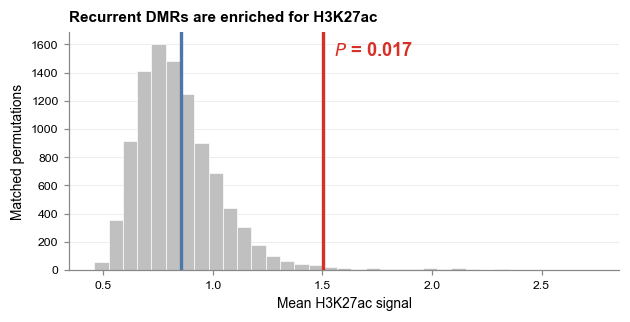

In [34]:
fig,ax=plt.subplots(figsize=(5.8,3.0))

obs_c=AMP if "AMP" in globals() else "#D73027"
exp_c="#4C78A8"
exp_h3=np.mean(null_h3)

ax.hist(null_h3,bins=35,color="#BDBDBD",edgecolor="white",
        linewidth=.45,alpha=.95)

# expected mean + observed
ax.axvline(exp_h3,color=exp_c,lw=2.2,zorder=4)
ax.axvline(obs_h3,color=obs_c,lw=2.2,zorder=5)

ax.set_xlabel("Mean H3K27ac signal")
ax.set_ylabel("Matched permutations")
ax.set_title("Recurrent DMRs are enriched for H3K27ac",
             loc="left",fontsize=10,fontweight="bold",pad=7)

ax.grid(axis="y",color="#D9D9D9",lw=.6,alpha=.5)
ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")
ax.tick_params(labelsize=8,color="#888888")

ymax=ax.get_ylim()[1]
ax.text(obs_h3+.05,ymax*.96,f"$P$ = {p_h3:.3f}",
        color=obs_c,ha="left",va="top",fontsize=12,fontweight="bold")

plt.tight_layout()
# plt.savefig(
#     OUT_ROOT / "h3k27ac_permutations.png",
#     dpi=300,bbox_inches="tight",facecolor="white"
# )
plt.show()

**Figure 5F** - cCRE overlap

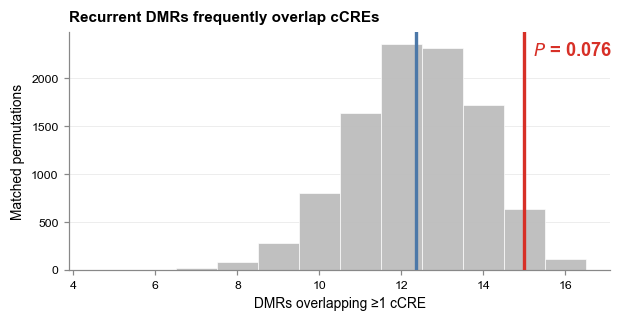

In [35]:
fig,ax=plt.subplots(figsize=(5.8,3.0))

obs_c=AMP if "AMP" in globals() else "#D73027"
exp_c="#4C78A8"
exp_ccre=np.mean(null_ccre)
bins=np.arange(null_ccre.min()-.5,null_ccre.max()+1.5,1)

ax.hist(null_ccre,bins=bins,color="#BDBDBD",edgecolor="white",
        linewidth=.45,alpha=.95)

# expected mean + observed
ax.axvline(exp_ccre,color=exp_c,lw=2.2,zorder=4)
ax.axvline(obs_ccre,color=obs_c,lw=2.2,zorder=5)

ax.set_xlabel("DMRs overlapping ≥1 cCRE")
ax.set_ylabel("Matched permutations")
ax.set_title("Recurrent DMRs frequently overlap cCREs",
             loc="left",fontsize=10,fontweight="bold",pad=7)

ax.grid(axis="y",color="#D9D9D9",lw=.6,alpha=.5)
ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
ax.spines["left"].set_color("#888888")
ax.spines["bottom"].set_color("#888888")
ax.tick_params(labelsize=8,color="#888888")

ymax=ax.get_ylim()[1]
ax.text(obs_ccre+.22,ymax*.96,f"$P$ = {p_ccre:.3f}",
        color=obs_c,ha="left",va="top",fontsize=12,fontweight="bold")

plt.tight_layout()
# plt.savefig(
#     OUT_ROOT / "ccre_permutations.png",
#     dpi=300,bbox_inches="tight",facecolor="white"
# )
plt.show()

### Sensitivity to the H3K27ac bin size (supplementary)

The H3K27ac test is repeated with the signal averaged over 100, 250, 500 and 1000 bp bins.

In [36]:
def bin_h3(df,b):
    x=df.copy()
    x["bin"]=x["start"]//b*b
    x=x.groupby("bin",as_index=False)["signal"].mean()
    x["pos"]=x["bin"]+b/2
    return x

H3_BINS={b:bin_h3(h3k27ac,b) for b in [100,250,500,1000]}

for b,x in H3_BINS.items():
    print(f"\n{b} bp bins | {len(x):,} rows")
    print(x["signal"].describe()[["mean","std","min","50%","max"]])


100 bp bins | 20,000 rows
mean     0.662212
std      0.883024
min      0.000000
50%      0.456840
max     32.805410
Name: signal, dtype: float64

250 bp bins | 8,000 rows
mean     0.662212
std      0.866656
min      0.000000
50%      0.454166
max     26.598016
Name: signal, dtype: float64

500 bp bins | 4,000 rows
mean     0.662212
std      0.839766
min      0.000000
50%      0.449899
max     20.619534
Name: signal, dtype: float64

1000 bp bins | 2,000 rows
mean     0.662212
std      0.800132
min      0.000000
50%      0.444491
max     16.350554
Name: signal, dtype: float64


In [37]:
def h3_test(H3,b,N_PERM=10000,seed=42):
    rng=np.random.default_rng(seed)

    def sig(s,e):
        z=H3[(H3["bin"]<e)&((H3["bin"]+b)>s)].copy()
        if z.empty:return np.nan
        z["w"]=np.minimum(z["bin"]+b,e)-np.maximum(z["bin"],s)
        return np.average(z["signal"],weights=z["w"])

    obs=np.mean([sig(s,e) for s,e in zip(DMRS.start,DMRS.end)])
    null=np.zeros(N_PERM)

    for p in range(N_PERM):
        vals=[]
        for _,d in DMRS.iterrows():
            L=int(d.end-d.start); target=int(d.n_tested_here)
            while True:
                s=int(rng.integers(UNIVERSE_START,UNIVERSE_END-L+1)); e=s+L
                n,_=interval_callability(s,e)
                if n>=MIN_TESTED and abs(n-target)<=TESTED_TOL:break
            vals.append(sig(s,e))
        null[p]=np.mean(vals)

    return obs,null.mean(),obs/null.mean(),(1+(null>=obs).sum())/(N_PERM+1),null

rows=[]; NULLS={}
for b in [100,250,500,1000]:
    o,n,f,p,null=h3_test(H3_BINS[b],b)
    rows.append([b,o,n,f,p]); NULLS[b]=null

res=pd.DataFrame(rows,columns=["bin_bp","observed","null_mean","fold_enrichment","empirical_p"])
display(res)

,bin_bp,observed,null_mean,fold_enrichment,empirical_p
0,100,1.500905,0.852993,1.759576,0.016898
1,250,1.488099,0.852528,1.745513,0.017598
2,500,1.469237,0.852571,1.723302,0.018398
3,1000,1.414356,0.852261,1.659533,0.024598


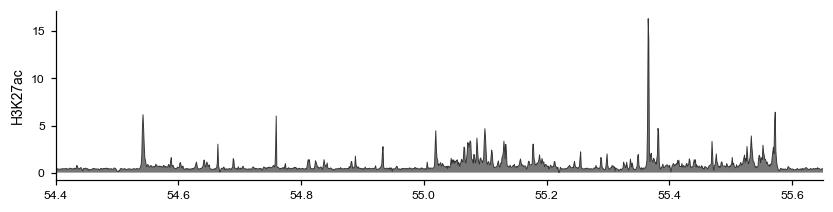

In [38]:
h3k27ac_1kb = H3_BINS[1000]       # 1-kb binned H3K27ac for a quick look at the track

fig, ax = plt.subplots(figsize=(9, 2))
ax.fill_between(h3k27ac_1kb["pos"] / 1e6, 0, h3k27ac_1kb["signal"], color="#555555", alpha=.8, linewidth=0)
ax.plot(h3k27ac_1kb["pos"] / 1e6, h3k27ac_1kb["signal"], color="#333333", lw=.6)
ax.set_xlim(54.4, 55.65)
ax.set_ylabel("H3K27ac")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 11. Methylation at the EGFR promoter and published regulatory elements (supplementary)

Coverage-weighted methylation (sum of methylated reads / sum of all reads over CpGs callable on both haplotypes) for the
amplified and chromosomal haplotype, at the EGFR promoter and at published EGFR regulatory elements. A negative delta means
the amplified haplotype is hypomethylated.

In [39]:
# ============================================================
# EGFR promoter delta methylation (amplified vs chromosomal)
# ============================================================
PROMOTER_START, PROMOTER_END = 55_018_667, 55_019_346
MIN_CPGS_PROMOTER = 3  # matches the spirit of MIN_CPGS_TO_COUNT_AS_TESTABLE used elsewhere

promoter_rows = []

for sample in MAIN_EGFR_SAMPLES:
    locus_name, chrom, start, end = next(
        x for x in SAMPLE_LOCI[sample] if x[0] == "chr7_EGFR"
    )
    cls = CLASSIFICATION.get((sample, locus_name), {})
    tumor = MASTER[sample]["Tumor"]

    if tumor is None or not cls:
        promoter_rows.append({"sample": sample, "status": "not_classified"})
        continue

    amp = build_haplotype_table(
        tumor, chrom, PROMOTER_START, PROMOTER_END, cls, "amp", DSS_THRESHOLD
    )
    other = build_haplotype_table(
        tumor, chrom, PROMOTER_START, PROMOTER_END, cls, "other", DSS_THRESHOLD
    )

    # joint callability: only keep CpG positions covered on BOTH haplotypes
    # at >= MIN_SITE_COVERAGE, same rule as the main DSS input
    amp_cov = amp[amp["N"] >= MIN_SITE_COVERAGE].set_index("pos")
    other_cov = other[other["N"] >= MIN_SITE_COVERAGE].set_index("pos")
    shared_pos = amp_cov.index.intersection(other_cov.index)

    if len(shared_pos) < MIN_CPGS_PROMOTER:
        promoter_rows.append({
            "sample": sample,
            "status": "insufficient_coverage",
            "n_shared_cpgs": len(shared_pos),
        })
        continue

    amp_shared = amp_cov.loc[shared_pos]
    other_shared = other_cov.loc[shared_pos]

    # coverage-weighted methylation, consistent with how DSS itself
    # treats N/X rather than an unweighted mean of per-CpG percentages
    amp_meth = 100 * amp_shared["X"].sum() / amp_shared["N"].sum()
    other_meth = 100 * other_shared["X"].sum() / other_shared["N"].sum()

    promoter_rows.append({
        "sample": sample,
        "status": "ok",
        "n_shared_cpgs": len(shared_pos),
        "amp_meth_pct": round(amp_meth, 2),
        "chromosomal_meth_pct": round(other_meth, 2),
        "delta_meth_pct": round(amp_meth - other_meth, 2),  # negative = amplified hypomethylated
    })

promoter_df = pd.DataFrame(promoter_rows)
display(promoter_df.sort_values("delta_meth_pct") if "delta_meth_pct" in promoter_df.columns else promoter_df)

,sample,status,n_shared_cpgs,amp_meth_pct,chromosomal_meth_pct,delta_meth_pct
3,UM137,ok,164,2.12,4.03,-1.91
5,UM159,ok,163,2.55,3.53,-0.98
2,UM130,ok,166,1.99,2.32,-0.33
11,UM029,ok,164,2.46,2.51,-0.04
1,UM124,ok,164,2.39,2.40,-0.01
9,UM244,ok,164,2.20,2.09,0.11
8,UM233,ok,154,1.48,1.23,0.25
6,UM170,ok,166,1.99,1.64,0.35
10,UM258,ok,157,2.33,1.89,0.44
4,UM146,ok,164,2.32,1.78,0.54


In [44]:
print('average promoter methylation on chromosome' , promoter_df['chromosomal_meth_pct'].mean())
print('average promoter methylation on amplified haplotype', promoter_df['amp_meth_pct'].mean())

average promoter methylation on chromosome 2.2318181818181815
average promoter methylation on amplified haplotype 2.139090909090909


In [41]:
# ============================================================
# Methylation across published EGFR regulatory regions
# amplified vs non-amplified haplotype
# ============================================================

MIN_CPGS_REGION = 3

REGULATORY_REGIONS = {
    # Hoogstrate et al. 2022 / Morton et al. (hg38 liftover)
    "Hoogstrate_E4": (54_752_307, 54_767_307),
    "Hoogstrate_E1": (54_882_307, 54_897_307),
    "Hoogstrate_E3": (55_104_307, 55_114_307),

    # Jameson et al. 2019
    "Jameson_CE1": (55_060_994, 55_066_815),
    "Jameson_CE2": (55_127_646, 55_135_347),

    # Tang et al. 2025
    "Tang_2025": (55_109_000, 55_112_000),

    # Sankar et al. 2026
    "Sankar_RE-A":       (55_254_266, 55_255_787),
    "Sankar_RE-B":       (55_365_155, 55_367_161),
    "Sankar_RE-D":       (55_964_516, 55_965_696),
    "Sankar_RE-E":       (55_018_783, 55_020_570),
    "Sankar_RE-F":       (55_571_369, 55_572_685),
    "Sankar_GBM39-hit1": (55_019_308, 55_020_307),
    "Sankar_GBM39-hit2": (55_365_308, 55_366_307),
}


region_rows = []

for region, (region_start, region_end) in REGULATORY_REGIONS.items():

    for sample in MAIN_EGFR_SAMPLES:

        locus_name, chrom, _, _ = next(
            x for x in SAMPLE_LOCI[sample]
            if x[0] == "chr7_EGFR"
        )

        cls = CLASSIFICATION.get((sample, locus_name), {})
        tumor = MASTER[sample]["Tumor"]

        if tumor is None or not cls:
            region_rows.append({
                "region": region,
                "sample": sample,
                "status": "not_classified",
            })
            continue

        amp = build_haplotype_table(
            tumor, chrom,
            region_start, region_end,
            cls, "amp",
            DSS_THRESHOLD
        )

        other = build_haplotype_table(
            tumor, chrom,
            region_start, region_end,
            cls, "other",
            DSS_THRESHOLD
        )

        # CpGs callable on BOTH haplotypes
        amp_cov = amp[
            amp["N"] >= MIN_SITE_COVERAGE
        ].set_index("pos")

        other_cov = other[
            other["N"] >= MIN_SITE_COVERAGE
        ].set_index("pos")

        shared_pos = amp_cov.index.intersection(
            other_cov.index
        )

        if len(shared_pos) < MIN_CPGS_REGION:
            region_rows.append({
                "region": region,
                "sample": sample,
                "status": "insufficient_coverage",
                "n_shared_cpgs": len(shared_pos),
            })
            continue

        amp_shared = amp_cov.loc[shared_pos]
        other_shared = other_cov.loc[shared_pos]

        # coverage-weighted methylation
        amp_meth = (
            100 *
            amp_shared["X"].sum() /
            amp_shared["N"].sum()
        )

        other_meth = (
            100 *
            other_shared["X"].sum() /
            other_shared["N"].sum()
        )

        region_rows.append({
            "region": region,
            "sample": sample,
            "start": region_start,
            "end": region_end,
            "n_shared_cpgs": len(shared_pos),
            "amp_meth_pct": amp_meth,
            "chromosomal_meth_pct": other_meth,
            "delta_meth_pct": amp_meth - other_meth,
            "status": "ok",
        })


regulatory_meth_df = pd.DataFrame(region_rows)

display(
    regulatory_meth_df[
        regulatory_meth_df["status"] == "ok"
    ].sort_values(
        ["region", "delta_meth_pct"]
    )
)

,region,sample,status,n_shared_cpgs,start,end,amp_meth_pct,chromosomal_meth_pct,delta_meth_pct
12,Hoogstrate_E1,UM116,ok,106,54882307.0,54897307.0,23.975010,33.725820,-9.750810
19,Hoogstrate_E1,UM215,ok,202,54882307.0,54897307.0,43.229709,48.778655,-5.548946
14,Hoogstrate_E1,UM130,ok,202,54882307.0,54897307.0,47.945267,53.335626,-5.390359
17,Hoogstrate_E1,UM159,ok,216,54882307.0,54897307.0,50.721051,54.450565,-3.729514
13,Hoogstrate_E1,UM124,ok,211,54882307.0,54897307.0,49.810263,53.238095,-3.427833
...,...,...,...,...,...,...,...,...,...
64,Tang_2025,UM146,ok,80,55109000.0,55112000.0,12.370502,27.498122,-15.127619
63,Tang_2025,UM137,ok,82,55109000.0,55112000.0,18.582408,32.737715,-14.155308
69,Tang_2025,UM244,ok,82,55109000.0,55112000.0,16.933578,25.998623,-9.065044
71,Tang_2025,UM029,ok,76,55109000.0,55112000.0,18.822469,18.701964,0.120505


In [45]:
regulatory_meth_df=regulatory_meth_df[regulatory_meth_df['sample'] != 'UM220']
regulatory_meth_df=regulatory_meth_df[regulatory_meth_df['sample'] != 'UM141']
regulatory_meth_df=regulatory_meth_df[regulatory_meth_df['status'] == 'ok']
regulatory_meth_df.to_csv(OUT_ROOT / 'regulatory_meth_df.csv', index=False)

In [46]:
ok = regulatory_meth_df[
    regulatory_meth_df["status"] == "ok"
].copy()

region_summary = (
    ok.groupby("region")
      .agg(
          n_tumors=("sample", "nunique"),
          mean_shared_cpgs=("n_shared_cpgs", "mean"),
          mean_amp_meth=("amp_meth_pct", "mean"),
          mean_chrom_meth=("chromosomal_meth_pct", "mean"),
          mean_delta=("delta_meth_pct", "mean"),
          median_delta=("delta_meth_pct", "median"),
      )
      .round(2)
      .sort_values("mean_delta")
)

display(region_summary)

,n_tumors,mean_shared_cpgs,mean_amp_meth,mean_chrom_meth,mean_delta,median_delta
region,,,,,,
Tang_2025,12,78.17,16.27,37.97,-21.70,-23.21
Hoogstrate_E3,12,221.33,59.80,69.10,-9.30,-9.75
Jameson_CE2,12,189.33,53.88,57.55,-3.67,-2.71
Hoogstrate_E1,11,193.73,45.69,49.00,-3.32,-2.75
Hoogstrate_E4,9,425.11,43.53,46.55,-3.02,-1.15
Jameson_CE1,11,134.45,70.98,72.36,-1.38,-0.37
Sankar_GBM39-hit2,10,204.10,1.98,2.44,-0.46,-0.12
Sankar_RE-B,10,294.30,2.01,2.35,-0.34,-0.16
Sankar_RE-A,12,240.58,7.55,7.87,-0.33,0.57


A finer view: methylation in 500-bp windows (100-bp step) across each region, averaging tumors equally (each tumor-haplotype
contributes one value per window), then plotted per region.

In [47]:
# within each window, calculate methylation separately
# for every sample/haplotype, then average equally

WINDOW = 500
STEP = 100
MIN_CPGS = 8

core_rows = []

for region, (region_start, region_end) in REGULATORY_REGIONS.items():

    sample_hap_tables = []

    for sample in MAIN_EGFR_SAMPLES:

        locus_name, chrom, _, _ = next(
            x for x in SAMPLE_LOCI[sample]
            if x[0] == "chr7_EGFR"
        )

        cls = CLASSIFICATION.get((sample, locus_name), {})
        tumor = MASTER[sample]["Tumor"]

        if tumor is None or not cls:
            continue

        for hap in ["amp", "other"]:

            x = build_haplotype_table(
                tumor, chrom,
                region_start, region_end,
                cls, hap,
                DSS_THRESHOLD
            )

            x = x[x["N"] >= MIN_SITE_COVERAGE].copy()

            if len(x):
                x["sample"] = sample
                x["hap"] = hap
                sample_hap_tables.append(x)

    if not sample_hap_tables:
        continue

    dat = pd.concat(sample_hap_tables)

    for start in range(region_start, region_end-WINDOW+1, STEP):

        end = start + WINDOW
        w = dat[(dat["pos"] >= start) & (dat["pos"] < end)]

        vals = []

        for (sample, hap), z in w.groupby(["sample","hap"]):

            if z["pos"].nunique() < MIN_CPGS:
                continue

            vals.append(
                100 * z["X"].sum() / z["N"].sum()
            )

        if len(vals) < 6:
            continue

        n_cpg = w["pos"].nunique()

        core_rows.append({
            "region": region,
            "start": start,
            "end": end,
            "n_cpgs": n_cpg,
            "cpgs_per_kb": n_cpg / (WINDOW/1000),
            "mean_meth_pct": np.mean(vals),
            "median_meth_pct": np.median(vals),
            "n_sample_haps": len(vals),
        })

core_scan_equal_df = pd.DataFrame(core_rows)

In [48]:
core_scan_equal_df.to_csv(OUT_ROOT / 'core_scan_equal_df.csv', index=False)

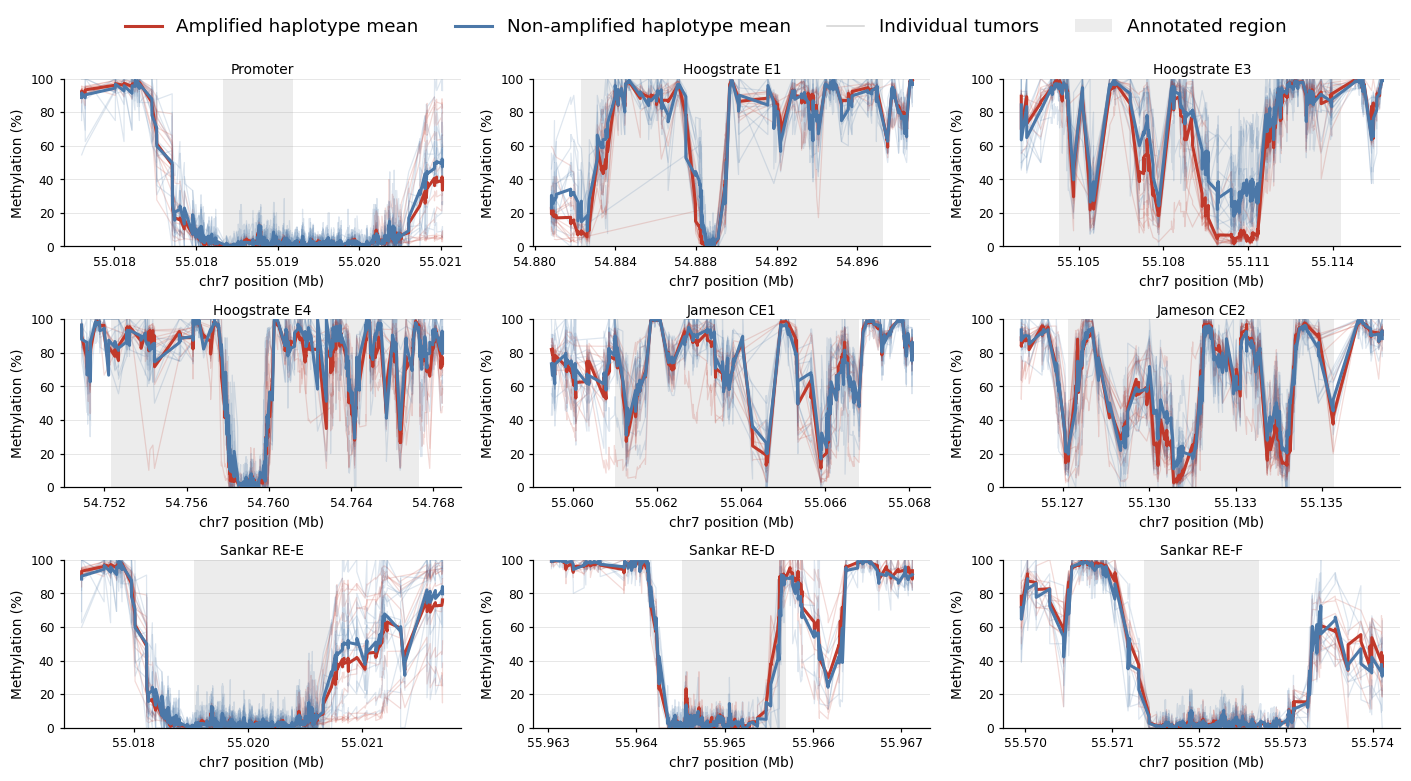

In [49]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

# ------------------------------------------------------------
# settings
# ------------------------------------------------------------
AMP_C   = "#C0392B"
OTHER_C = "#4C78A8"
SHADE_C = "#BDBDBD"

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
})

# choose the panels you want
REGIONS = {
    "Promoter":      (55_018_667, 55_019_346),
    "Hoogstrate E3": (55_104_307, 55_114_307),
    "Jameson CE2":   (55_127_646, 55_135_347),
    "Sankar RE-E":   (55_018_783, 55_020_570),
    # add/remove if you want:
    # "Hoogstrate E1": (54_882_307, 54_897_307),
    # "Hoogstrate E4": (54_752_307, 54_767_307),
    # "Jameson CE1":   (55_060_994, 55_066_815),
    # "Tang 2025":     (55_109_000, 55_112_000),
}

REGIONS = {
    "Promoter":      (55_018_667, 55_019_346),
    "Hoogstrate E1": (54_882_307, 54_897_307),
    "Hoogstrate E3": (55_104_307, 55_114_307),
    "Hoogstrate E4": (54_752_307, 54_767_307),
    "Jameson CE1":   (55_060_994, 55_066_815),
    "Jameson CE2":   (55_127_646, 55_135_347),
    "Sankar RE-E":   (55_018_783, 55_020_570),
    "Sankar RE-D":   (55_964_516, 55_965_696),
    "Sankar RE-F":   (55_571_369, 55_572_685),
}

FLANK = 1500
MIN_SHARED_CPGS = 3
SMOOTH = 1   # set >1 if you want rolling smoothing of means

# ------------------------------------------------------------
# helper: build per-sample methylation track for one region
# ------------------------------------------------------------
def get_region_track(sample, region_name, start, end, flank=FLANK):
    locus_name, chrom, _, _ = next(
        x for x in SAMPLE_LOCI[sample] if x[0] == "chr7_EGFR"
    )
    cls   = CLASSIFICATION.get((sample, locus_name), {})
    tumor = MASTER[sample]["Tumor"]
    if tumor is None or not cls:
        return None

    amp = build_haplotype_table(
        tumor, chrom, start - flank, end + flank, cls, "amp", DSS_THRESHOLD
    )
    oth = build_haplotype_table(
        tumor, chrom, start - flank, end + flank, cls, "other", DSS_THRESHOLD
    )

    amp = amp[amp["N"] >= MIN_SITE_COVERAGE][["pos", "X", "N"]].copy()
    oth = oth[oth["N"] >= MIN_SITE_COVERAGE][["pos", "X", "N"]].copy()
    if amp.empty or oth.empty:
        return None

    m = amp.merge(oth, on="pos", suffixes=("_amp", "_other"))
    if len(m) < MIN_SHARED_CPGS:
        return None

    m["amp_meth"]   = 100 * m["X_amp"]   / m["N_amp"]
    m["other_meth"] = 100 * m["X_other"] / m["N_other"]
    m["sample"]     = sample
    m["region"]     = region_name
    return m[["region", "sample", "pos", "amp_meth", "other_meth"]]

# ------------------------------------------------------------
# build plotting dataframe
# ------------------------------------------------------------
tracks = []
for region_name, (start, end) in REGIONS.items():
    for sample in MAIN_EGFR_SAMPLES:
        t = get_region_track(sample, region_name, start, end)
        if t is not None:
            tracks.append(t)

track_df = pd.concat(tracks, ignore_index=True)
track_df["pos_mb"] = track_df["pos"] / 1e6

# ------------------------------------------------------------
# plotting
# ------------------------------------------------------------
def plot_region_panels(track_df, regions=REGIONS, ncols=2):
    region_list = [r for r in regions if r in set(track_df["region"])]
    n = len(region_list)
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(4.3 * ncols, 2.35 * nrows),
        squeeze=False
    )
    axes = axes.ravel()

    for ax, region_name in zip(axes, region_list):
        start, end = regions[region_name]
        sub = track_df[track_df["region"] == region_name].copy()

        # shade the annotated region
        ax.axvspan(start / 1e6, end / 1e6, color=SHADE_C, alpha=0.28, lw=0, zorder=0)

        # faint individual tumor lines
        for sample, g in sub.groupby("sample"):
            g = g.sort_values("pos")
            ax.plot(g["pos_mb"], g["amp_meth"],   color=AMP_C,   lw=0.8, alpha=0.18, zorder=1)
            ax.plot(g["pos_mb"], g["other_meth"], color=OTHER_C, lw=0.8, alpha=0.18, zorder=1)

        # bold means
        mean_df = (
            sub.groupby("pos", as_index=False)[["amp_meth", "other_meth"]]
            .mean()
            .sort_values("pos")
        )
        mean_df["pos_mb"] = mean_df["pos"] / 1e6

        if SMOOTH > 1:
            mean_df["amp_meth"] = mean_df["amp_meth"].rolling(SMOOTH, center=True, min_periods=1).mean()
            mean_df["other_meth"] = mean_df["other_meth"].rolling(SMOOTH, center=True, min_periods=1).mean()

        ax.plot(mean_df["pos_mb"], mean_df["amp_meth"],   color=AMP_C,   lw=2.0, zorder=3)
        ax.plot(mean_df["pos_mb"], mean_df["other_meth"], color=OTHER_C, lw=2.0, zorder=3)

        ax.set_title(region_name, fontsize=9, pad=3)
        ax.set_ylim(0, 100)
        ax.set_ylabel("Methylation (%)")
        ax.set_xlabel("chr7 position (Mb)")
        ax.grid(axis="y", lw=0.35, alpha=0.35, color="grey")
        ax.tick_params(length=2.5)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.xaxis.set_major_formatter(FormatStrFormatter("%.3f"))
        ax.get_xaxis().get_offset_text().set_visible(False)

    # turn off unused panels
    for ax in axes[len(region_list):]:
        ax.axis("off")

    handles = [
        Line2D([0], [0], color=AMP_C, lw=2, label="Amplified haplotype mean"),
        Line2D([0], [0], color=OTHER_C, lw=2, label="Non-amplified haplotype mean"),
        Line2D([0], [0], color="black", lw=1, alpha=0.18, label="Individual tumors"),
        Patch(facecolor=SHADE_C, edgecolor="none", alpha=0.28, label="Annotated region"),
    ]
    fig.legend(
        handles=handles,
        loc="upper center",
        ncol=4,
        frameon=False,
        bbox_to_anchor=(0.5, 1.01),
        fontsize=12
    )

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.savefig(OUT_ROOT / 'average_methylation_regulatory_regions.png', dpi=300)
    plt.show()

plot_region_panels(track_df, ncols=3)

## 12. Methylation along the reconstructed ecDNA (supplementary)

For tumors whose ecDNA was reconstructed with CoRAL, methylation of the amplified haplotype is drawn around the circular
ecDNA, following the order and orientation of the reconstructed segments (`<sample>_amplicon<N>_cycles.txt`). Skipped if the
CoRAL output folder is not present.

In [50]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

ECDNA_DIR=Path("coral_cycles")      # EDIT: folder with CoRAL <sample>_amplicon<N>_cycles.txt files
METH_DIR=DATA_DIR
EGFR=("chr7",55_019_017,55_211_628)

# ============================================================
# PARSE CoRAL
# ============================================================

def parse_coral_cycle(path,cycle=1):
    segdict={}; cycles={}

    with open(path) as f:
        for line in f:
            line=line.strip()

            if line.startswith("Segment\t"):
                p=line.split("\t")
                segdict[int(p[1])]={
                    "segment":int(p[1]),
                    "chrom":p[2],
                    "start":int(p[3]),
                    "end":int(p[4])
                }

            elif line.startswith("Cycle="):
                m=re.search(r"Cycle=(\d+);.*?Segments=([^;]+)",line)
                if m:
                    cid=int(m.group(1))
                    cycles[cid]=[
                        (int(x[:-1]),x[-1])
                        for x in m.group(2).split(",")
                        if x[:-1].isdigit() and x[-1] in "+-"
                    ]

    if cycle not in cycles:
        raise ValueError(f"Cycle {cycle} not found; available cycles: {sorted(cycles)}")

    out=[]
    for sid,strand in cycles[cycle]:
        if sid==0: continue
        if sid not in segdict:
            raise ValueError(f"Segment {sid} used in cycle but not defined")
        d=segdict[sid].copy()
        d["strand"]=strand
        out.append(d)

    return out


# ============================================================
# PREPARE METHYLATION + CIRCULAR COORDINATES
# ============================================================

def prepare_tumor_ecDNA(sample,amplicon=1,cycle=1,min_total=200,min_ratio=1.5):
    cycle_file=ECDNA_DIR/f"{sample}_amplicon{amplicon}_cycles.txt"
    meth_file=METH_DIR/f"{sample}_Tumor_master_cpg_table.csv.gz"

    segs=parse_coral_cycle(cycle_file,cycle)

    df=pd.read_csv(meth_file)
    df=df[(df["threshold"]=="20pct")&(df["N"]>0)].copy()

    # CpGs contained in any cycle segment
    keep=np.zeros(len(df),bool)
    for d in segs:
        keep |= (
            df["chrom"].eq(d["chrom"]) &
            df["pos"].ge(d["start"]) &
            df["pos"].lt(d["end"])
        )
    eco=df[keep].copy()

    # classify amplified vs chromosomal HP within each phase set
    cov=eco.groupby(["ps","hp"])["N"].sum().unstack(fill_value=0)
    cls={}

    for ps,r in cov.iterrows():
        h=sorted(r.index,key=lambda z:r[z],reverse=True)
        if len(h)<2: continue
        hi,lo=h[:2]
        if r[hi]+r[lo]>=min_total and r[hi]>=min_ratio*max(r[lo],1):
            cls[ps]=(hi,lo)

    eco["state"]=eco.apply(
        lambda r:
            "amp" if r["ps"] in cls and r["hp"]==cls[r["ps"]][0]
            else ("chr" if r["ps"] in cls and r["hp"]==cls[r["ps"]][1] else None),
        axis=1
    )

    amp=(eco[eco["state"]=="amp"]
         .groupby(["chrom","pos"],as_index=False)[["N","X"]].sum())

    amp["meth"]=100*amp["X"]/amp["N"]

    # map into cycle order, respecting orientation
    parts=[]; offset=0; boundaries=[]

    for d in segs:
        z=amp[
            (amp["chrom"]==d["chrom"]) &
            amp["pos"].ge(d["start"]) &
            amp["pos"].lt(d["end"])
        ].copy()

        L=d["end"]-d["start"]

        z["local_bp"]=(
            z["pos"]-d["start"]
            if d["strand"]=="+"
            else d["end"]-1-z["pos"]
        )

        z["circ_bp"]=offset+z["local_bp"]
        z["segment"]=d["segment"]
        z["strand"]=d["strand"]

        parts.append(z)
        offset+=L
        boundaries.append(offset)

    x=pd.concat(parts,ignore_index=True).sort_values("circ_bp").reset_index(drop=True)
    x["theta"]=2*np.pi*x["circ_bp"]/offset

    return x,segs,offset,boundaries


# ============================================================
# PLOT
# ============================================================

def plot_tumor_ecDNA(
    sample,
    amplicon=1,
    cycle=1,
    junction=None,                  # e.g. ("4+","2+")
    smooth_window=75,
    show_span=True,
    show_line=True,
    show_points=True,
    show_segment_boundaries=False,
    show_segment_labels=False,
    show_egfr=True
):
    x,segs,total,bounds=prepare_tumor_ecDNA(sample,amplicon,cycle)

    r0,dr=1,.42
    x=x.copy()
    x["r"]=r0+dr*x["meth"]/100

    fig,ax=plt.subplots(figsize=(6,6),subplot_kw={"projection":"polar"})
    ax.set_theta_offset(np.pi/2)
    ax.set_theta_direction(-1)

    th=np.linspace(0,2*np.pi,1200)

    # guide rings
    for f in [0,.25,.5,.75,1]:
        ax.plot(
            th,np.full_like(th,r0+dr*f),
            color="#D9D9D9",
            lw=.55 if f not in [.5,1] else .8,
            zorder=0
        )

    # ecDNA backbone
    ax.plot(th,np.full_like(th,r0),color="#F57C00",lw=4,zorder=1)

    # raw CpGs
    if show_points:
        ax.scatter(
            x["theta"],x["r"],
            s=4,color="#D73027",
            alpha=.04,lw=0,zorder=4
        )

    # circular smoothing
    if smooth_window and len(x)>smooth_window:
        w=int(smooth_window)
        if w%2==0: w+=1
        h=w//2

        v=x["meth"].to_numpy()
        pad=np.r_[v[-h:],v,v[:h]]
        sm=(pd.Series(pad)
            .rolling(w,center=True,min_periods=1)
            .median()
            .to_numpy()[h:h+len(v)])

        ts=np.r_[x["theta"].to_numpy(),x["theta"].iloc[0]+2*np.pi]
        rs=np.r_[r0+dr*sm/100,r0+dr*sm[0]/100]

        if show_span:
            ax.fill_between(
                ts,r0,rs,
                color="#E6A23C",
                alpha=.20,lw=0,zorder=2
            )

        if show_line:
            ax.plot(
                ts,rs,
                color="#C98D1E",
                lw=.5,alpha=.75,zorder=3
            )

    # EGFR annotation wherever cycle overlaps EGFR
    if show_egfr:
        offset=0
        eg_angles=[]

        for d in segs:
            L=d["end"]-d["start"]

            if d["chrom"]==EGFR[0]:
                a=max(d["start"],EGFR[1])
                b=min(d["end"],EGFR[2])

                if b>a:
                    if d["strand"]=="+":
                        q1,q2=a-d["start"],b-d["start"]
                    else:
                        q1,q2=d["end"]-b,d["end"]-a

                    t1=2*np.pi*(offset+q1)/total
                    t2=2*np.pi*(offset+q2)/total
                    tt=np.linspace(t1,t2,200)

                    ax.plot(
                        tt,np.full_like(tt,.99),
                        color="#2C6DB2",lw=8,
                        solid_capstyle="round",
                        zorder=5
                    )
                    eg_angles.extend(tt)

            offset+=L

        if eg_angles:
            ang=np.angle(np.mean(np.exp(1j*np.asarray(eg_angles))))
            ax.text(
                ang,.9,"EGFR",
                color="#2C6DB2",
                ha="center",va="center",
                fontsize=9,fontstyle="italic",
                fontweight="bold"
            )

    # optional segment-transition ticks
    if show_segment_boundaries:
        for b in bounds[:-1]:
            t=2*np.pi*b/total
            ax.plot(
                [t,t],[r0-.015,r0+.035],
                color="#777777",lw=.8,zorder=6
            )

    # optional segment labels
    if show_segment_labels:
        starts=np.r_[0,bounds[:-1]]
        for d,s0,e0 in zip(segs,starts,bounds):
            t=2*np.pi*((s0+e0)/2)/total
            ax.text(
                t,.87,
                f'{d["segment"]}{d["strand"]}',
                fontsize=7,color="#666666",
                ha="center",va="center"
            )

    # explicitly supplied biologic junction only
    if junction is not None:
        labels=[f'{d["segment"]}{d["strand"]}' for d in segs]
        found=False

        for i,left in enumerate(labels):
            right=labels[(i+1)%len(labels)]

            if (left,right)==tuple(junction):
                t=0 if i==len(labels)-1 else 2*np.pi*bounds[i]/total

                ax.plot(
                    [t,t],[r0,r0+dr+.03],
                    color="black",lw=2.2,zorder=7
                )

                ax.text(
                    t,r0+dr+.05,
                    "ecDNA junction",
                    ha="center",va="bottom",
                    fontsize=8
                )

                found=True
                break

        if not found:
            raise ValueError(
                f"Junction {junction} not found in cycle. "
                f"Cycle order: {' -> '.join(labels)} -> {labels[0]}"
            )

    # methylation labels near 0°, offset from any line
    lt=np.deg2rad(8)
    ax.text(lt,r0+dr*.5,"50%",fontsize=7,color="#777777",ha="left",va="center")
    ax.text(lt,r0+dr*.98,"100%",fontsize=7,color="#777777",ha="left",va="center")

    ax.set_ylim(.78,r0+dr+.08)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.spines["polar"].set_visible(False)

    ax.set_title(
        f"{sample} | reconstructed ecDNA methylation landscape",
        pad=18,fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

    labels=[f'{d["segment"]}{d["strand"]}' for d in segs]
    print("Cycle:", " → ".join(labels), "→", labels[0])

    return x,segs

In [51]:
if not ECDNA_DIR.exists():
    print(f'{ECDNA_DIR} not found - skipping ecDNA methylation plots')
else:
    plot_tumor_ecDNA(
        "UM159",
        amplicon=1,
        cycle=1,
        junction=("4+","2+"),
        smooth_window=75,
        show_span=True,
        show_line=True,
        show_points=True
    )


    plot_tumor_ecDNA(
        "UM130",
        amplicon=2,
        junction=None,
        show_segment_boundaries=True
    )

coral_cycles not found - skipping ecDNA methylation plots


## Appendix: building the per-CpG tables (run on the compute server)

The input tables for this notebook are produced from the haplotagged, methylation-tagged BAMs of each tumor and its matched
blood (restricted to chr7:49-59 Mb plus the ecDNA intervals). `modkit extract full` reports each CpG call with its
modification probability; read haplotype (`HP`) and phase set (`PS`) tags come from WhatsHap haplotagging of the
blood-phased variants (see Methods). The script below joins the two and counts methylated (`X`) and total (`N`) reads per
CpG, haplotype, phase set and probability threshold. It is run once per tumor and once per blood sample, for example:

```bash
python build_master_cpg_table.py --sample SAMPLE --tissue Tumor --chrom chr7 \
    --bam SAMPLE_Tumor_methylation_haplotagged.bam --modkit /path/to/modkit \
    --ref GRCh38.fa --outdir tables/SAMPLE
```

The cell below only writes the script to disk; it is not needed to run the analysis above.

In [52]:
%%writefile build_master_cpg_table.py
#!/usr/bin/env python3
"""
build_master_cpg_table.py

Master per-CpG table builder. Deliberately decides nothing about amplicon
coordinates, phase-set classification, or amplified/chromosomal haplotype
assignment -- that's all downstream analysis, done locally where it's cheap
to change your mind (see analysis/methylation_dmr/).

For every CpG covered in the haplotagged, methylation-called BAM, at every
haplotype and phase set, counts coverage (N) and methylated count (X)
under several confidence thresholds. One row per (pos, hp, ps, threshold).

Corresponds to Methods -> "Haplotype-resolved CpG methylation analysis":
methylation probability >0.80 -> methylated, <0.20 -> unmethylated,
intermediate calls excluded (the "20pct" threshold below implements this:
keep calls with mod_qual <=0.20 or >=0.80, i.e. outside the [0.20,0.80]
excluded band).

Output columns: sample, tissue, chrom, pos, hp, ps, threshold, N, X

Usage:
    python build_master_cpg_table.py \
        --sample SAMPLE1 --tissue Tumor --chrom chr7 \
        --bam SAMPLE1_Tumor_methylation_haplotagged.bam \
        --modkit /path/to/modkit --ref GRCh38.fa \
        --outdir out/SAMPLE1
(run once per tissue -- Tumor and Blood -- per sample)
"""

import argparse
import subprocess
from pathlib import Path

import pandas as pd
import pysam

THRESHOLDS = {
    "none": None,     # simple >=0.5 majority call
    "10pct": 0.10,    # keep calls with mod_qual<=0.10 or >=0.90
    "20pct": 0.20,    # keep calls with mod_qual<=0.20 or >=0.80 (paper's primary threshold)
    "40pct": 0.40,
}


def parse_args():
    p = argparse.ArgumentParser()
    p.add_argument("--sample", required=True)
    p.add_argument("--tissue", required=True, choices=["Tumor", "Blood"])
    p.add_argument("--chrom", required=True, help="Restrict to this chromosome")
    p.add_argument("--bam", required=True, help="Haplotagged, methylation-called BAM")
    p.add_argument("--modkit", required=True, help="Path to modkit binary")
    p.add_argument("--ref", required=True, help="Reference FASTA")
    p.add_argument("--outdir", required=True)
    return p.parse_args()


def ensure_extract(bam_path, modkit_bin, ref_fasta, sample, tissue, work_dir):
    extract_tsv = work_dir / f"{sample}_{tissue}_haplotagged_extract.tsv"
    if extract_tsv.exists():
        print(f"Reusing cached extract: {extract_tsv}")
        return extract_tsv
    print(f"\nRunning modkit extract full on {tissue} ({bam_path})...")
    cmd = [str(modkit_bin), "extract", "full", str(bam_path), str(extract_tsv),
           "--reference", str(ref_fasta), "--cpg", "--mapped-only", "--force"]
    result = subprocess.run(cmd, capture_output=True, text=True)
    print(result.stdout[-2000:])
    if result.stderr.strip():
        print(result.stderr[-2000:])
    if result.returncode != 0:
        raise RuntimeError(f"modkit extract failed for {tissue}, code {result.returncode}")
    return extract_tsv


def get_hp_ps_map(bam_path, chrom):
    bam = pysam.AlignmentFile(str(bam_path), "rb")
    hp_map, ps_map = {}, {}
    for read in bam.fetch(chrom):
        if read.is_unmapped or read.is_secondary or read.is_supplementary:
            continue
        if read.has_tag("HP") and read.has_tag("PS"):
            hp_map[read.query_name] = int(read.get_tag("HP"))
            ps_map[read.query_name] = int(read.get_tag("PS"))
    bam.close()
    return hp_map, ps_map


def build_master_table(extract_tsv, hp_map, ps_map, sample, tissue, chrom):
    print(f"\nProcessing {tissue}...")
    long_rows = []

    for chunk in pd.read_csv(
        extract_tsv, sep="\t", chunksize=2_000_000,
        usecols=["read_id", "ref_position", "chrom", "mod_qual", "mod_code"],
    ):
        chunk = chunk[(chunk["mod_code"] == "m") & (chunk["chrom"] == chrom)]
        chunk = chunk.assign(hp=chunk["read_id"].map(hp_map), ps=chunk["read_id"].map(ps_map))
        chunk = chunk.dropna(subset=["hp", "ps"])
        chunk["hp"] = chunk["hp"].astype(int)
        chunk["ps"] = chunk["ps"].astype(int)

        for thresh_label, thresh in THRESHOLDS.items():
            if thresh is None:
                sub = chunk.assign(is_meth=(chunk["mod_qual"] >= 0.5).astype(int))
            else:
                sub = chunk[(chunk["mod_qual"] <= thresh) | (chunk["mod_qual"] >= 1 - thresh)]
                sub = sub.assign(is_meth=(sub["mod_qual"] >= 1 - thresh).astype(int))
            agg = (sub.groupby(["ref_position", "hp", "ps"])
                      .agg(N=("is_meth", "size"), X=("is_meth", "sum"))
                      .reset_index())
            agg["threshold"] = thresh_label
            long_rows.append(agg)

    master = pd.concat(long_rows, ignore_index=True)
    master = (master.groupby(["ref_position", "hp", "ps", "threshold"], as_index=False)
                     .agg(N=("N", "sum"), X=("X", "sum")))
    master = master.rename(columns={"ref_position": "pos"})
    master.insert(0, "chrom", chrom)
    master.insert(0, "tissue", tissue)
    master.insert(0, "sample", sample)
    return master.sort_values(["pos", "hp", "threshold"]).reset_index(drop=True)


def main():
    args = parse_args()
    outdir = Path(args.outdir)
    outdir.mkdir(parents=True, exist_ok=True)

    extract_tsv = ensure_extract(args.bam, args.modkit, args.ref, args.sample, args.tissue, outdir)

    print("\n" + "=" * 60)
    print("Reading HP/PS tags")
    print("=" * 60)
    hp_map, ps_map = get_hp_ps_map(args.bam, args.chrom)
    print(f"{args.tissue} reads with HP+PS: {len(hp_map):,}")

    master = build_master_table(extract_tsv, hp_map, ps_map, args.sample, args.tissue, args.chrom)

    out_path = outdir / f"{args.sample}_{args.tissue}_master_cpg_table.csv.gz"
    master.to_csv(out_path, index=False, compression="gzip")

    print("\n" + "=" * 60)
    print("SUMMARY")
    print("=" * 60)
    print(f"{args.tissue} master table: {len(master):,} rows -> {out_path}")
    print(f"Unique phase sets: {master['ps'].nunique()}")
    print(f"Position range: {master['pos'].min():,} - {master['pos'].max():,}")
    print("\nNothing amplicon-specific or classification-specific was decided here --")
    print("phase-set classification, amp/chromosomal assignment, and DMR-table")
    print("building all happen downstream (see analysis/methylation_dmr/) and can")
    print("be redone with different parameters without rerunning this step.")


if __name__ == "__main__":
    main()

Writing build_master_cpg_table.py
